
# EDA – Pedidos Ya (Logística)
Análisis exploratorio de las bases **pedidos**, **riders** y **turnos** para el caso *Delivery y tecnología – PedidosYa*.

**Problema de la consigna:** la tasa de aceptación de órdenes es de ~70% (Mercado A) y los un-dispatch (el rider acepta y luego no finaliza) son ~2%. Efectos: (A) la orden no aceptada afecta el **nivel de servicio**; (B) se reduce la **disponibilidad** de riders. Supuestos: una orden simultánea por rider; es viable capitalizar el aumento de UTR en ahorro de CPO. **Pregunta:** propuesta para maximizar la aceptación y la ejecución de las órdenes, y estimar el impacto en nivel de servicio y costos.

**Nota sobre los datos (aclaración de la profesora):** los datos están transformados por confidencialidad pero mantienen las proporciones. Por eso las magnitudes absolutas (pago, pago por hora, ahorros) **no se presentan como dinero real**: los impactos se expresan en **%** o en **minutos**. El análisis es de **una sola zona** (no hay análisis geográfico). UTR y horas conectadas se calculan combinando turnos y pedidos.

**Definiciones de la profesora:** *tasa de rechazo* (un-dispatch pre-aceptación) = Σ `pre_accept_undispatch` / Σ notificaciones totales; *tasa de un-dispatch post-aceptación* = Σ `post_accept_undispatchs` / Σ órdenes aceptadas. Ambas se calculan sobre **todas las filas** de `pedidos` (los un-dispatch están en las filas `queued`, ver 9.1). Qué cuenta como "notificaciones totales" no está claro: **revisar** (9.1).

**Hilo conductor:** disponibilidad de riders → aceptación → ejecución (reasignación / un-dispatch) → nivel de servicio (Delivery Time, cancelaciones) → eficiencia (UTR, CPO).

Estructura:
1. Carga y calidad de datos
2. Construcción de variables (tiempos por etapa, pago total, hora/día)
3. Tendencias temporales
4. Relaciones entre variables (pedidos)
5. Riders (vehículo, antigüedad, aceptación)
6. Turnos y oferta vs demanda
7. Productividad (pedidos × turnos × riders) y UTR agregado
8. Relación entre turnos, riders y pedidos
9. Un-dispatch: tasas oficiales y relación con el nivel de servicio
10. Escenarios de impacto (nivel de servicio, UTR y CPO)
11. Validación de hipótesis
12. Hallazgos



## Hipótesis de trabajo
_Objetivo: maximizar la aceptación y la ejecución de las órdenes. Meta numérica: **revisar** (la consigna da el punto de partida: ~70% de aceptación y ~2% de un-dispatch)._

| # | Eje | Hipótesis | Variables | Sección |
|---|---|---|---|---|
| H1 | Disponibilidad | La oferta real de riders es menor que la planificada, con la mayor brecha en los picos | turnos planificados vs reales, pedidos por hora | 8 |
| H2 | Disponibilidad | La oferta acompaña la forma de la demanda; el problema es el cumplimiento, no el perfil horario | riders por hora vs pedidos por hora | 6, 8 |
| H3 | Aceptación | Aceptar más se asocia con más pedidos por hora conectada (UTR) | `tasa_aceptacion`, UTR agregado | 7, 8, 10 |
| H4 | Aceptación | El pago por pedido sigue la distancia, no el tiempo total ni la espera: los pedidos con espera larga son menos atractivos | `pago_base`, distancias, `t_espera_local`, `t_total` | 4 |
| H5 | Aceptación | Los incentivos se concentran en ciertas franjas (noche, picos de cena) y no se relacionan con el esfuerzo del pedido | `pago_incentivos`, `hora`, distancias | 3, 4 |
| H6 | Aceptación | Existe un perfil de rider (`avg_batch` alto) con menor aceptación, más no-show y menos UTR | `avg_batch`, `tasa_aceptacion`, no-show | 5, 8 |
| H7 | Aceptación | La antigüedad mejora puntualidad y productividad, pero no la aceptación | `tenure_in_weeks` | 5, 8 |
| H8 | Ejecución | El un-dispatch (pre y post aceptación) es medible sumando todas las filas de `pedidos` y se concentra en ciertos segmentos (hora, día, vehículo, antigüedad, aceptación) | `pre_accept_undispatch`, `post_accept_undispatchs` | 9 |
| H9 | Ejecución | Los pedidos con un-dispatch tienen mayor tiempo de aceptación y total, y más cancelaciones | `t_aceptacion`, `t_total`, `order_status` | 9 |
| H10 | Ejecución | Mayor distancia al retiro y mayor espera en el local se asocian con más un-dispatch | `pu_distance`, `t_espera_local` | 9 |
| H11 | Impacto | Subir la aceptación reduce los rechazos por orden y el Delivery Time, y mejora UTR y CPO | escenarios | 10 |


In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 50); pd.set_option('display.float_format', '{:,.2f}'.format)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': .3})

# === RUTAS ===
RUTA_PEDIDOS = 'Base de Pedidos.csv'
RUTA_RIDERS  = 'Base de Riders.csv'
RUTA_TURNOS  = 'Base de Turnos - NUEVA! (1).csv'
MUESTRA_SCATTER = 50_000   # filas para scatterplots

## 1. Carga y calidad de datos

In [2]:
COLS_FECHA_PED = ['creacion_pedido','creacion_transicion','rider_notified_at','rider_accepted_at','rider_near_pickup_at',
                  'rider_picked_up_at','rider_near_dropoff_at','rider_dropped_off_at']
pedidos = pd.read_csv(RUTA_PEDIDOS, low_memory=False)
for col in COLS_FECHA_PED:
    pedidos[col] = pd.to_datetime(pedidos[col], format='mixed', errors='coerce')

riders = pd.read_csv(RUTA_RIDERS)

# Turnos: CSV con inicio/fin planificado y real; los turnos sin horario real (no se conectaron) quedan con NaT
turnos = pd.read_csv(RUTA_TURNOS, dtype={'shift_id': str})
turnos['rider_id'] = turnos['rider_id'].astype('Int64')
for col in ['inicio_turno_planificado','inicio_turno_real','fin_turno_planificado','fin_turno_real']:
    turnos[col] = pd.to_datetime(turnos[col], errors='coerce')
turnos['inicio'] = turnos['inicio_turno_real']
turnos['fin']    = turnos['fin_turno_real']
turnos['duracion_hs'] = (turnos['fin'] - turnos['inicio']).dt.total_seconds() / 3600

for nombre, df in [('pedidos', pedidos), ('riders', riders), ('turnos', turnos)]:
    print(f'{nombre}: {df.shape}')

pedidos: (1217343, 21)
riders: (8736, 5)
turnos: (78377, 9)


In [3]:
# Nulos
for nombre, df in [('pedidos', pedidos), ('riders', riders), ('turnos', turnos)]:
    n = df.isna().sum(); n = n[n > 0]
    print(f'--- Nulos en {nombre} ---'); print((pd.DataFrame({'nulos': n, '%': n / len(df) * 100})) if len(n) else 'sin nulos')

--- Nulos en pedidos ---
                       nulos    %
rider_near_dropoff_at   2398 0.20
rider_dropped_off_at    5833 0.48
--- Nulos en riders ---
           nulos     %
avg_batch   1048 12.00
--- Nulos en turnos ---
                   nulos     %
inicio_turno_real  27127 34.61
fin_turno_real     27127 34.61
inicio             27127 34.61
fin                27127 34.61
duracion_hs        27127 34.61


In [4]:
# ¿1 fila = 1 pedido o hay varias filas por pedido (transiciones)?
print('filas:', len(pedidos), '| id_pedido únicos:', pedidos['id_pedido'].nunique())
print(pedidos['order_status'].value_counts(dropna=False), '\n')
print(pedidos['transicion'].value_counts(dropna=False).head(15))
print('\nriders únicos en pedidos:', pedidos['id_repartidor'].nunique(), '| comercios:', pedidos['id_comercio'].nunique())
print('id_repartidor != transicion_id_repartidor:', (pedidos['id_repartidor'] != pedidos['transicion_id_repartidor']).mean().round(4))
print('duplicados riders:', riders['id_repartidor'].duplicated().sum(), '| duplicados shift_id:', turnos['shift_id'].duplicated().sum())

filas: 1217343 | id_pedido únicos: 329196
order_status
completed    1210706
cancelled       6634
pending            3
Name: count, dtype: int64 

transicion
accepted       346554
near_pickup    340117
picked_up      329196
queued         201476
Name: count, dtype: int64

riders únicos en pedidos: 5288 | comercios: 2640
id_repartidor != transicion_id_repartidor: 0.1874
duplicados riders: 446 | duplicados shift_id: 0


In [5]:
# Una fila por pedido (última transición registrada). REVISAR este criterio según la consigna.
pedidos = pedidos.sort_values('creacion_transicion')
ped = pedidos.drop_duplicates('id_pedido', keep='last').copy()
# Los un-dispatch están en las filas 'queued' (ver 9.1); en la última fila de cada pedido valen 0.
# Por eso en `ped` se reemplazan por la SUMA sobre todas las filas del pedido.
cols_u = ['pre_accept_undispatch', 'post_accept_undispatchs']
ped = ped.drop(columns=cols_u).join(pedidos.groupby('id_pedido')[cols_u].sum(), on='id_pedido')
print('Pedidos únicos:', len(ped))
print('Σ pre_accept_undispatch  en ped:', int(ped[cols_u[0]].sum()), '| en pedidos (todas las filas):', int(pedidos[cols_u[0]].sum()))
print('Σ post_accept_undispatchs en ped:', int(ped[cols_u[1]].sum()), '| en pedidos (todas las filas):', int(pedidos[cols_u[1]].sum()))

Pedidos únicos: 329196
Σ pre_accept_undispatch  en ped: 184476 | en pedidos (todas las filas): 184476
Σ post_accept_undispatchs en ped: 17000 | en pedidos (todas las filas): 17000


## 2. Construcción de variables

In [6]:
mins = lambda a, b: (ped[a] - ped[b]).dt.total_seconds() / 60
ped['t_aceptacion']   = mins('rider_accepted_at',    'rider_notified_at')    # min que tarda en aceptar
ped['t_a_local']      = mins('rider_near_pickup_at', 'rider_accepted_at')    # min hasta llegar al local
ped['t_espera_local'] = mins('rider_picked_up_at',   'rider_near_pickup_at') # min esperando en el local
ped['t_viaje']        = mins('rider_dropped_off_at', 'rider_picked_up_at')   # min de retiro a entrega
ped['t_total']        = mins('rider_dropped_off_at', 'rider_notified_at')    # notificación a entrega
ped['pago_total']     = ped[['pago_base','pago_rendimiento','pago_incentivos']].sum(axis=1)
ped['dist_total']     = ped['pu_distance'] + ped['do_distance']
ped['undispatch_total'] = ped['pre_accept_undispatch'] + ped['post_accept_undispatchs']
ped['entregado']      = ped['rider_dropped_off_at'].notna()
ped['fecha'] = ped['rider_notified_at'].dt.date
ped['hora']  = ped['rider_notified_at'].dt.hour
ped['dow']   = ped['rider_notified_at'].dt.dayofweek   # 0 = lunes
ped['semana']= ped['rider_notified_at'].dt.to_period('W').dt.start_time

TIEMPOS = ['t_aceptacion','t_a_local','t_espera_local','t_viaje','t_total']
print('Tiempos negativos por variable:'); print((ped[TIEMPOS] < 0).sum())
print('\nDescriptivos:'); print(ped[TIEMPOS + ['pu_distance','do_distance','pago_base','pago_rendimiento','pago_incentivos','pago_total']].describe(percentiles=[.05,.5,.95,.99]).T)

Tiempos negativos por variable:
t_aceptacion      0
t_a_local         0
t_espera_local    0
t_viaje           0
t_total           0
dtype: int64

Descriptivos:
                      count     mean    std  min     5%      50%      95%  \
t_aceptacion     329,196.00     0.26   0.30 0.00   0.02     0.17     0.85   
t_a_local        329,196.00     3.16   2.84 0.00   0.00     2.79     8.27   
t_espera_local   329,196.00     5.29   4.90 0.00   0.59     3.86    14.66   
t_viaje          327,855.00     9.69   4.67 1.00   4.01     8.84    18.17   
t_total          327,855.00    18.41   7.11 1.03   9.28    17.27    31.24   
pu_distance      329,196.00   506.01 444.01 0.00  36.00   397.00 1,321.00   
do_distance      329,196.00 1,352.15 994.74 0.00 248.00 1,098.00 3,298.00   
pago_base        329,196.00    18.06   4.91 0.00  12.12    16.89    26.66   
pago_rendimiento 329,196.00     1.37   1.23 0.00   0.00     1.46     3.59   
pago_incentivos  329,196.00     1.57   3.50 0.00   0.00     0.00     8

In [7]:
# Limpieza: sólo entregados, tiempos >= 0 y se recorta el 1% superior (REVISAR umbral)
ok = ped['entregado'] & (ped[TIEMPOS] >= 0).all(axis=1)
lim = ped.loc[ok, TIEMPOS].quantile(.99)
ok &= (ped[TIEMPOS] <= lim).all(axis=1)
pe = ped[ok].copy()
print(f'Se conservan {len(pe):,} de {len(ped):,} pedidos ({len(pe)/len(ped):.1%}). No entregados: {(~ped.entregado).sum():,}')

Se conservan 314,541 de 329,196 pedidos (95.5%). No entregados: 1,341


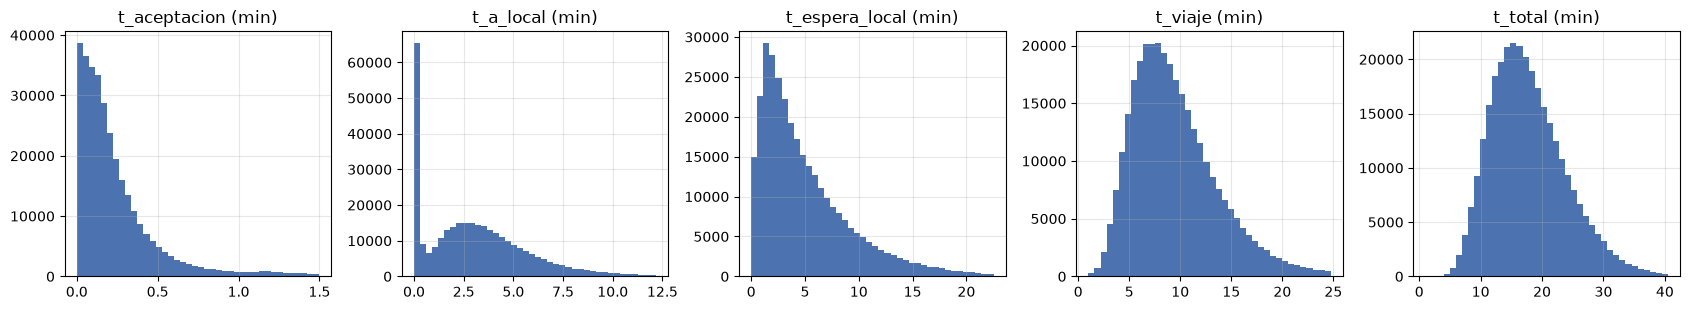

In [8]:
fig, ax = plt.subplots(1, 5, figsize=(17, 3.2))
for a, c in zip(ax, TIEMPOS):
    a.hist(pe[c], bins=40, color='#4c72b0'); a.set_title(c + ' (min)')
plt.tight_layout(); plt.show()

## 3. Tendencias temporales
_Hipótesis: H5 (incentivos por franja) y contexto de H1 (picos de demanda)._

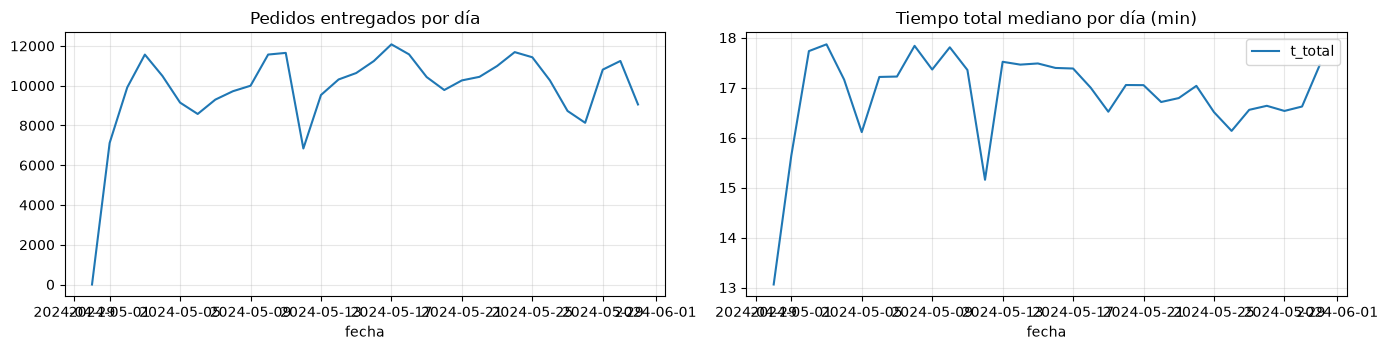

In [9]:
diario = pe.groupby('fecha').agg(pedidos=('id_pedido','count'), t_total=('t_total','median'), pago=('pago_total','mean'))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
diario['pedidos'].plot(ax=ax[0], title='Pedidos entregados por día')
diario[['t_total']].plot(ax=ax[1], title='Tiempo total mediano por día (min)')
plt.tight_layout(); plt.show()

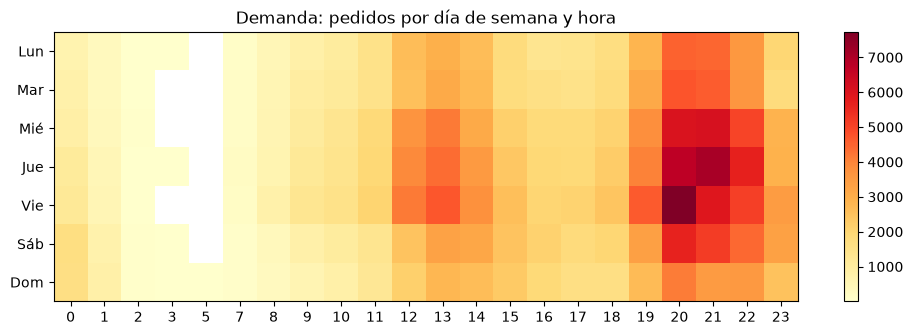

In [10]:
heat = pe.pivot_table(index='dow', columns='hora', values='id_pedido', aggfunc='count').reindex(range(7))
fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(heat.values, aspect='auto', cmap='YlOrRd'); ax.grid(False)
ax.set_yticks(range(7)); ax.set_yticklabels(['Lun','Mar','Mié','Jue','Vie','Sáb','Dom'])
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns)
ax.set_title('Demanda: pedidos por día de semana y hora'); plt.colorbar(im); plt.show()

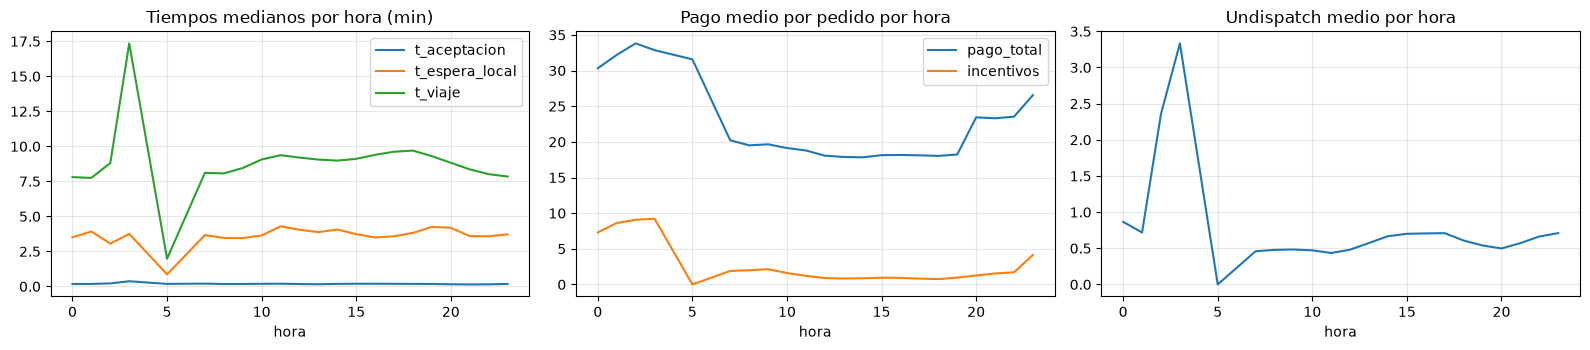

,pedidos,t_aceptacion,t_espera_local,t_viaje,pago_total,incentivos,undispatch
hora,,,,,,,
0,7712,0.17,3.51,7.80,30.32,7.30,0.87
1,3453,0.18,3.92,7.75,32.20,8.62,0.72
2,255,0.22,3.05,8.81,33.81,9.07,2.36
3,6,0.37,3.75,17.35,32.86,9.21,3.33
5,1,0.18,0.86,1.98,31.57,0.00,0.00
7,906,0.20,3.67,8.11,20.22,1.90,0.46
8,3515,0.17,3.46,8.07,19.51,1.99,0.48
9,6610,0.17,3.45,8.45,19.65,2.14,0.48
10,8137,0.19,3.64,9.06,19.14,1.60,0.47


In [11]:
por_hora = pe.groupby('hora').agg(pedidos=('id_pedido','count'), t_aceptacion=('t_aceptacion','median'),
                                  t_espera_local=('t_espera_local','median'), t_viaje=('t_viaje','median'),
                                  pago_total=('pago_total','mean'), incentivos=('pago_incentivos','mean'),
                                  undispatch=('undispatch_total','mean'))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
por_hora[['t_aceptacion','t_espera_local','t_viaje']].plot(ax=ax[0], title='Tiempos medianos por hora (min)')
por_hora[['pago_total','incentivos']].plot(ax=ax[1], title='Pago medio por pedido por hora')
por_hora['undispatch'].plot(ax=ax[2], title='Undispatch medio por hora')
plt.tight_layout(); plt.show()
por_hora

## 4. Relaciones entre variables (pedidos)
_Hipótesis: H4 (pago vs esfuerzo), H5 y H10. `pu_distance` = rider → local; `do_distance` = local → cliente. Las columnas de undispatch dan 0 en esta tabla (una fila por pedido): se reconstruyen en la sección 9._

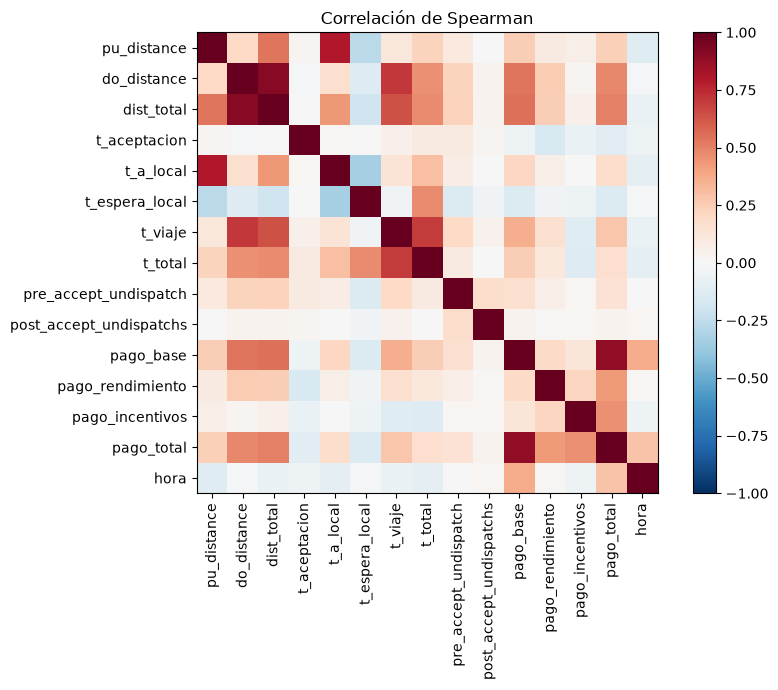

In [12]:
VARS = ['pu_distance','do_distance','dist_total','t_aceptacion','t_a_local','t_espera_local','t_viaje','t_total',
        'pre_accept_undispatch','post_accept_undispatchs','pago_base','pago_rendimiento','pago_incentivos','pago_total','hora']
corr = pe[VARS].corr(method='spearman')
fig, ax = plt.subplots(figsize=(9, 7)); im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(VARS))); ax.set_xticklabels(VARS, rotation=90); ax.set_yticks(range(len(VARS))); ax.set_yticklabels(VARS)
ax.set_title('Correlación de Spearman'); plt.colorbar(im); plt.tight_layout(); plt.show()

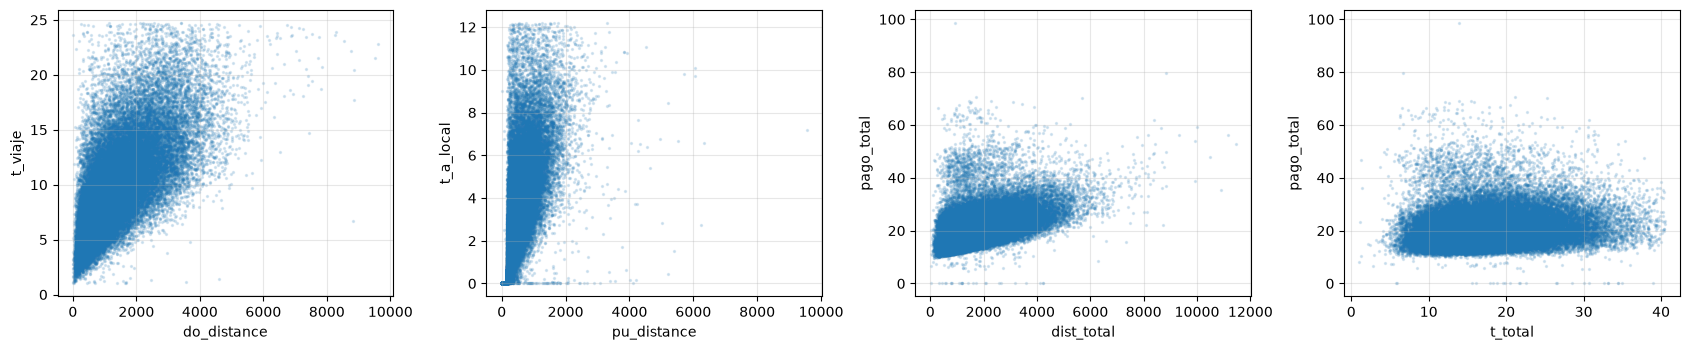

In [13]:
s = pe.sample(min(MUESTRA_SCATTER, len(pe)), random_state=0)
pares = [('do_distance','t_viaje'), ('pu_distance','t_a_local'), ('dist_total','pago_total'), ('t_total','pago_total')]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, (x, y) in zip(ax, pares):
    a.scatter(s[x], s[y], s=2, alpha=.15); a.set_xlabel(x); a.set_ylabel(y)
plt.tight_layout(); plt.show()

In [14]:
# Efecto de los undispatch y del pago sobre los tiempos
for v in ['pre_accept_undispatch','post_accept_undispatchs']:
    g = pe.assign(g=pe[v].clip(upper=3)).groupby('g')[['t_aceptacion','t_total']].agg(['median','count'])
    print(f'\n{v} (3 = 3 o más)'); print(g)
pe['dec_incentivo'] = pd.qcut(pe['pago_incentivos'].rank(method='first'), 5, labels=['Q1','Q2','Q3','Q4','Q5'])
print('\nIncentivo (quintiles) vs tiempo de aceptación y espera'); print(pe.groupby('dec_incentivo', observed=True)[['pago_incentivos','t_aceptacion','t_total']].median())


pre_accept_undispatch (3 = 3 o más)
  t_aceptacion         t_total        
        median   count  median   count
g                                     
0         0.16  231883   16.70  231883
1         0.19   47270   17.39   47270
2         0.20   16717   18.02   16717
3         0.20   18671   18.89   18671

post_accept_undispatchs (3 = 3 o más)
  t_aceptacion         t_total        
        median   count  median   count
g                                     
0         0.17  301045   17.01  301045
1         0.19   11863   16.90   11863
2         0.18    1216   17.75    1216
3         0.14     417   19.32     417

Incentivo (quintiles) vs tiempo de aceptación y espera
               pago_incentivos  t_aceptacion  t_total
dec_incentivo                                        
Q1                        0.00          0.18    17.98
Q2                        0.00          0.18    17.65
Q3                        0.00          0.18    17.14
Q4                        1.79          0.16    16.7

             pedidos  espera_med  espera_p90  t_total  peso_espera
id_comercio                                                       
96787926          38       11.28       14.87    27.46         0.41
105902808         39       11.17       15.51    25.81         0.43
35314266         740       10.05       15.43    24.45         0.41
91322970          34        9.95       16.12    25.34         0.39
58210734         123        9.50       15.27    22.62         0.42
41945124          60        9.33       14.31    18.96         0.49
57958926          52        8.88       15.88    21.64         0.41
35060394         519        8.85       14.96    22.50         0.39
108762222        150        8.83       14.11    23.75         0.37
30108858          60        8.77       17.59    20.67         0.42

Peso mediano de la espera en el tiempo total: 0.21 | dispersión de espera mediana entre comercios (desvío): 1.53


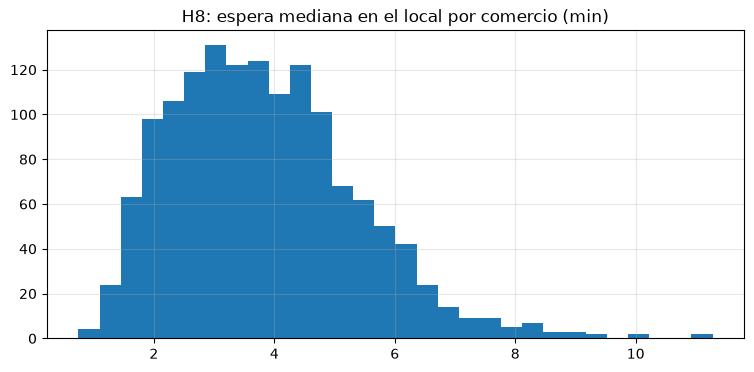

In [15]:
# H8: espera en el local por comercio (comercios con al menos 30 pedidos)
com = pe.groupby('id_comercio').agg(pedidos=('id_pedido','count'), espera_med=('t_espera_local','median'), espera_p90=('t_espera_local', lambda x: x.quantile(.9)),
                                   t_total=('t_total','median')).query('pedidos >= 30')
com['peso_espera'] = com['espera_med'] / com['t_total']
print(com.sort_values('espera_med', ascending=False).head(10))
print('\nPeso mediano de la espera en el tiempo total:', com['peso_espera'].median().round(2),
      '| dispersión de espera mediana entre comercios (desvío):', com['espera_med'].std().round(2))
com['espera_med'].hist(bins=30); plt.title('H8: espera mediana en el local por comercio (min)'); plt.show()

## 5. Riders
_Hipótesis: H3, H6, H7._

                   count unique        top  freq          mean           std  \
id_repartidor   8,736.00    NaN        NaN   NaN 85,436,928.94 37,737,110.11   
vehicle_name        8736      5  Bicicleta  5072           NaN           NaN   
tasa_aceptacion 8,736.00    NaN        NaN   NaN          0.80          0.20   
avg_batch       7,688.00    NaN        NaN   NaN          4.45          1.73   
tenure_in_weeks 8,736.00    NaN        NaN   NaN         59.12         64.39   

                         min           25%           50%            75%  \
id_repartidor   4,009,062.00 54,351,312.00 95,024,496.00 120,091,969.50   
vehicle_name             NaN           NaN           NaN            NaN   
tasa_aceptacion         0.03          0.67          0.85           1.00   
avg_batch               1.00          3.00          4.57           5.53   
tenure_in_weeks         0.00         10.00         33.14          91.29   

                           max  
id_repartidor   135,168,522.00  
ve

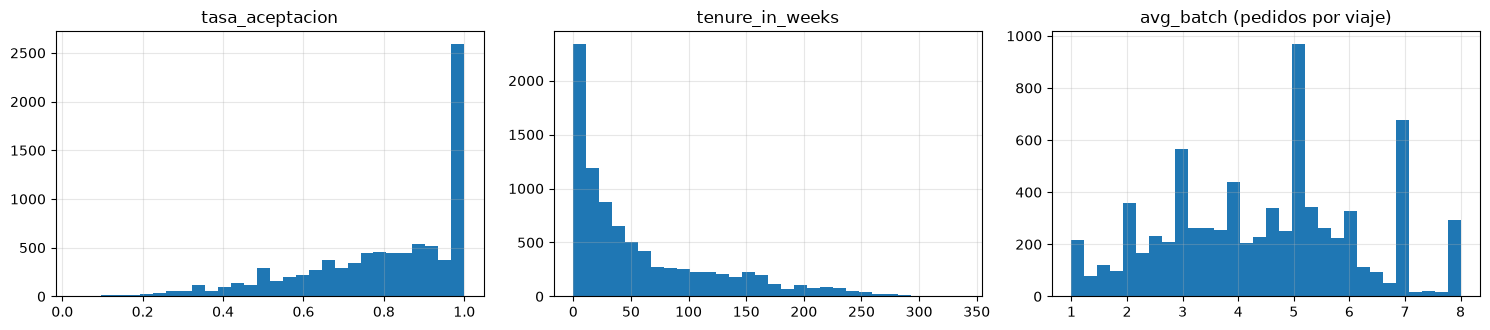

                 tasa_aceptacion  avg_batch  tenure_in_weeks
tasa_aceptacion             1.00      -0.26            -0.02
avg_batch                  -0.26       1.00            -0.42
tenure_in_weeks            -0.02      -0.42             1.00


In [16]:
print(riders.describe(include='all').T)
print(riders['vehicle_name'].value_counts())
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
riders['tasa_aceptacion'].hist(ax=ax[0], bins=30); ax[0].set_title('tasa_aceptacion')
riders['tenure_in_weeks'].hist(ax=ax[1], bins=30); ax[1].set_title('tenure_in_weeks')
riders['avg_batch'].hist(ax=ax[2], bins=30); ax[2].set_title('avg_batch (pedidos por viaje)')
plt.tight_layout(); plt.show()
print(riders[['tasa_aceptacion','avg_batch','tenure_in_weeks']].corr(method='spearman'))

In [17]:
pr = pe.merge(riders, on='id_repartidor', how='left')
print('Pedidos sin rider en tabla riders:', pr['vehicle_name'].isna().sum())
por_veh = pr.groupby('vehicle_name').agg(pedidos=('id_pedido','count'), riders=('id_repartidor','nunique'), dist_entrega=('do_distance','median'),
                                         t_viaje=('t_viaje','median'), t_total=('t_total','median'), pago_total=('pago_total','mean'))
por_veh['pedidos_por_rider'] = por_veh['pedidos'] / por_veh['riders']
por_veh

Pedidos sin rider en tabla riders: 96


,pedidos,riders,dist_entrega,t_viaje,t_total,pago_total,pedidos_por_rider
vehicle_name,,,,,,,
Automovil,769,40,"1,302.00",9.44,17.66,20.62,19.23
Bicicleta,195259,3104,883.00,8.17,16.39,19.59,62.91
CAFE - Bici,4415,35,855.00,7.98,16.50,19.70,126.14
CAFE - Moto,686,22,"1,428.00",9.00,17.49,22.79,31.18
Motocicleta,138476,2145,"1,480.00",9.56,17.76,22.90,64.56


In [18]:
pr['tenure_grupo'] = pd.cut(pr['tenure_in_weeks'], [-1, 4, 12, 26, 52, 1e9], labels=['<=4 sem','5-12','13-26','27-52','>52'])
print(pr.groupby('tenure_grupo', observed=True).agg(pedidos=('id_pedido','count'), t_aceptacion=('t_aceptacion','median'),
      t_total=('t_total','median'), pago_total=('pago_total','mean'), undispatch=('undispatch_total','mean')))
r_ped = pr.groupby('id_repartidor').agg(pedidos=('id_pedido','count'), t_total=('t_total','median'), undisp=('undispatch_total','mean'),
                                        pago=('pago_total','mean')).join(riders.set_index('id_repartidor'))
print(r_ped[['pedidos','t_total','undisp','pago','tasa_aceptacion','avg_batch','tenure_in_weeks']].corr(method='spearman').round(2))

              pedidos  t_aceptacion  t_total  pago_total  undispatch
tenure_grupo                                                        
<=4 sem          4363          0.16    18.29       19.88        0.53
5-12            14081          0.16    17.85       19.97        0.61
13-26           42276          0.18    17.59       19.80        0.60
27-52           76828          0.17    16.90       20.73        0.61
>52            202057          0.17    16.75       21.36        0.59
                 pedidos  t_total  undisp  pago  tasa_aceptacion  avg_batch  \
pedidos             1.00    -0.13    0.27  0.14            -0.25      -0.17   
t_total            -0.13     1.00    0.08  0.08             0.12       0.03   
undisp              0.27     0.08    1.00  0.27             0.08      -0.12   
pago                0.14     0.08    0.27  1.00             0.21      -0.43   
tasa_aceptacion    -0.25     0.12    0.08  0.21             1.00      -0.39   
avg_batch          -0.17     0.03   -0.12 -

## 6. Turnos y oferta vs demanda
_Hipótesis: H2._

Turnos sin fechas: 27127 (34.6%)
duracion_hs <= 0: 0 | > 12 hs: 10
count   51,250.00
mean         3.87
std          1.73
min          0.00
25%          3.37
50%          3.87
75%          4.64
max        265.26
Name: duracion_hs, dtype: float64


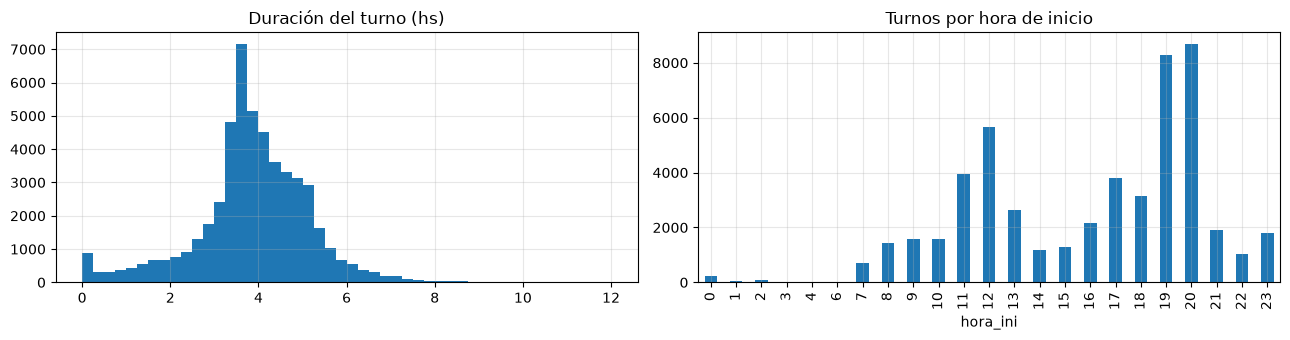

In [19]:
print('Turnos sin fechas:', turnos['inicio'].isna().sum(), f"({turnos['inicio'].isna().mean():.1%})")
tu = turnos.dropna(subset=['inicio','fin']).copy()
print('duracion_hs <= 0:', (tu['duracion_hs'] <= 0).sum(), '| > 12 hs:', (tu['duracion_hs'] > 12).sum())
print(tu['duracion_hs'].describe())
tu['hora_ini'] = tu['inicio'].dt.hour
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
tu['duracion_hs'].clip(upper=12).hist(ax=ax[0], bins=48); ax[0].set_title('Duración del turno (hs)')
tu['hora_ini'].value_counts().sort_index().plot.bar(ax=ax[1], title='Turnos por hora de inicio')
plt.tight_layout(); plt.show()

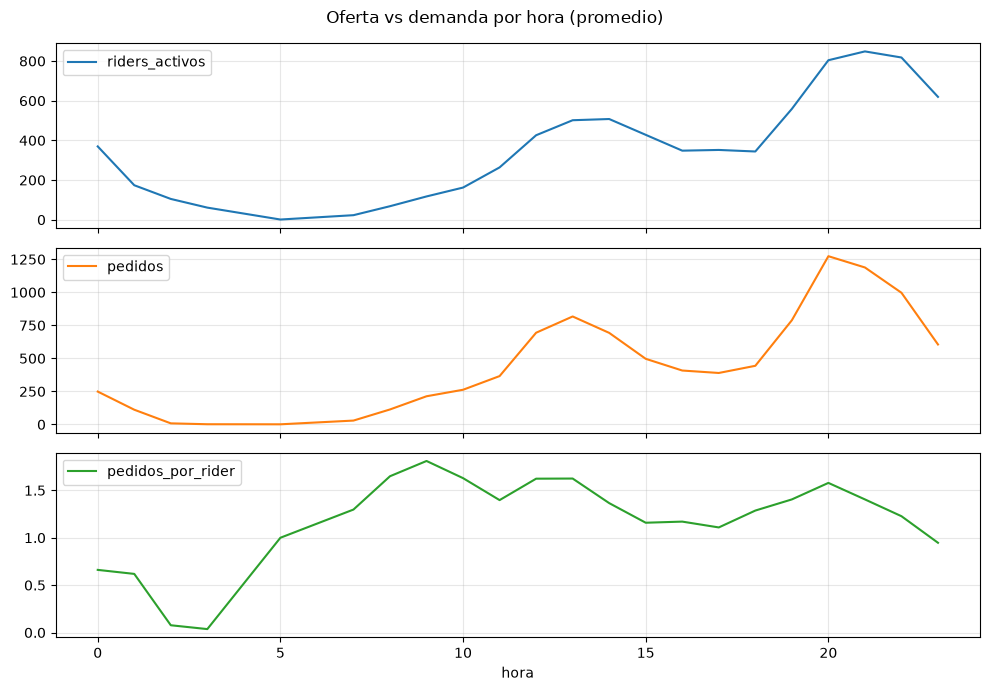

Correlación horaria riders activos vs pedidos: 0.93


In [20]:
# Riders conectados por hora (turnos que cubren cada hora) vs pedidos
tu['h0'] = tu['inicio'].dt.floor('h'); tu['h1'] = tu['fin'].dt.floor('h')
tu = tu[(tu['h1'] >= tu['h0']) & (tu['duracion_hs'] <= 24)]
rep = tu.loc[tu.index.repeat(((tu['h1'] - tu['h0']).dt.total_seconds() // 3600 + 1).astype(int))].copy()
rep['h'] = rep['h0'] + pd.to_timedelta(rep.groupby(level=0).cumcount(), unit='h')
oferta = rep.groupby('h')['rider_id'].nunique().rename('riders_activos')
demanda = pe.groupby(pe['rider_notified_at'].dt.floor('h'))['id_pedido'].count().rename('pedidos')
od = pd.concat([oferta, demanda], axis=1).dropna(); od['pedidos_por_rider'] = od['pedidos'] / od['riders_activos']
od['hora'] = od.index.hour
od.groupby('hora')[['riders_activos','pedidos','pedidos_por_rider']].mean().plot(subplots=True, figsize=(10, 7), title='Oferta vs demanda por hora (promedio)')
plt.tight_layout(); plt.show()
print('Correlación horaria riders activos vs pedidos:', od[['riders_activos','pedidos']].corr(method='spearman').iloc[0, 1].round(2))

## 7. Productividad (pedidos × turnos × riders) y UTR
_Hipótesis: H3 y H6._

**UTR = Σ pedidos entregados / Σ horas conectadas** (no medianas ni promedios de ratios). Horas conectadas = duración real del turno (`inicio_turno_real` a `fin_turno_real`) dentro del período en común de turnos y pedidos; cada pedido se asigna a un turno con la lógica de 8.2 (rider con un turno real que cubre `rider_notified_at`). Se excluyen turnos con duración real <= 0 o > 24 hs. Los resultados rider-nivel (7.2, 8.4) se mantienen para las correlaciones.

In [21]:
# 7.0 Base común: período en común y asignación pedido -> turno (lógica usada también en la sección 8)
ped_ok = ped.dropna(subset=['id_repartidor', 'rider_notified_at']).copy()
ped_ok['id_repartidor'] = ped_ok['id_repartidor'].astype('int64')
tr = turnos.dropna(subset=['rider_id']).copy(); tr['rider_id'] = tr['rider_id'].astype('int64')
real = tr.dropna(subset=['inicio_turno_real', 'fin_turno_real']).sort_values('inicio_turno_real')
dup = riders.groupby('id_repartidor')['vehicle_name'].nunique()
print(f"id_repartidor duplicados en riders: {riders['id_repartidor'].duplicated().sum()} | con vehículo distinto entre duplicados: {(dup > 1).sum()}")
riders_u = riders.drop_duplicates('id_repartidor')      # se conserva la primera fila de cada rider
TRAMOS_ACEPT = [0, .5, .7, .85, .999, 1.0]; ETIQ_ACEPT = ['<=50%', '50-70%', '70-85%', '85-<100%', '100%']

DESDE = max(ped_ok['rider_notified_at'].min(), tr['inicio_turno_planificado'].min())
HASTA = min(ped_ok['rider_notified_at'].max(), tr['fin_turno_planificado'].max())

p = ped_ok[ped_ok['rider_notified_at'].between(DESDE, HASTA)].sort_values('rider_notified_at')
m = pd.merge_asof(p[['id_pedido','id_repartidor','rider_notified_at','t_aceptacion','entregado','pago_total','hora','dow']],
                  real[['shift_id','rider_id','inicio_turno_real','fin_turno_real']],
                  left_on='rider_notified_at', right_on='inicio_turno_real', left_by='id_repartidor', right_by='rider_id', direction='backward')
m['en_turno'] = m['fin_turno_real'] >= m['rider_notified_at']
m.loc[~m['en_turno'], 'shift_id'] = np.nan
m['rider_con_turnos'] = m['id_repartidor'].isin(set(real['rider_id']))
m['causa'] = np.where(m['en_turno'], 'dentro de un turno',
              np.where(m['rider_con_turnos'], 'rider con turnos, pero fuera de horario', 'rider sin ningún turno'))

sh = tr[tr['inicio_turno_planificado'].between(DESDE, HASTA)].copy()
sh['conectado'] = sh['inicio_turno_real'].notna()
sh['dur_plan_hs'] = (sh['fin_turno_planificado'] - sh['inicio_turno_planificado']).dt.total_seconds() / 3600
sh['dur_real_hs'] = (sh['fin_turno_real'] - sh['inicio_turno_real']).dt.total_seconds() / 3600
sh['demora_inicio_min'] = (sh['inicio_turno_real'] - sh['inicio_turno_planificado']).dt.total_seconds() / 60
sh['dif_fin_min'] = (sh['fin_turno_real'] - sh['fin_turno_planificado']).dt.total_seconds() / 60
cnt = m.groupby('shift_id').agg(pedidos=('id_pedido', 'count'), entregados=('entregado', 'sum'), pago=('pago_total', 'sum'))
sh = sh.merge(cnt, left_on='shift_id', right_index=True, how='left')
sh[['pedidos', 'entregados', 'pago']] = sh[['pedidos', 'entregados', 'pago']].fillna(0)
sh['ped_hora'] = sh['pedidos'] / sh['dur_real_hs'].where(sh['dur_real_hs'] > .25)
# Turnos válidos para el UTR (conectados, 0 < duración <= 24 hs)
sh['dur_ok'] = sh['conectado'] & sh['dur_real_hs'].between(0, 24, inclusive='neither')
sh['horas_utr'] = sh['dur_real_hs'].where(sh['dur_ok'], 0)
sh['ped_utr'] = sh['entregados'].where(sh['dur_ok'], 0)
print(f'Período en común: {DESDE:%Y-%m-%d} -> {HASTA:%Y-%m-%d}')
print(f"Turnos del período: {len(sh):,} | conectados: {sh['conectado'].sum():,} | válidos para el UTR: {sh['dur_ok'].sum():,} (excluidos por duración: {(sh['conectado'] & ~sh['dur_ok']).sum():,})")
print(f"Pedidos del período: {len(m):,} | asignados a un turno: {m['en_turno'].sum():,} ({m['en_turno'].mean():.1%})")

id_repartidor duplicados en riders: 446 | con vehículo distinto entre duplicados: 446
Período en común: 2024-04-30 -> 2024-05-31
Turnos del período: 78,173 | conectados: 51,106 | válidos para el UTR: 51,105 (excluidos por duración: 1)
Pedidos del período: 329,196 | asignados a un turno: 288,268 (87.6%)


UTR agregado total: 1.452 pedidos entregados por hora conectada (Σ 287,012 pedidos / Σ 197,694 hs)
Control: horas repartidas por hora 197,694 vs horas de turno 197,694
Control: pedidos en el numerador 287,012 vs Σ entregados de los turnos 287,012

Picos de demanda (4 horas con más pedidos): [13, 20, 21, 22] | UTR en picos: 1.530 | fuera de picos: 1.396

UTR por hora del día:
    entregados     horas  UTR
0     7,450.00  7,286.28 1.02
1     3,310.00  3,885.86 0.85
2       235.00  1,919.30 0.12
3         5.00    268.28 0.02
5         1.00      2.17 0.46
7       649.00    353.07 1.84
8     2,404.00  1,296.92 1.85
9     5,316.00  2,880.59 1.84
10    6,741.00  4,161.17 1.62
11    9,477.00  6,107.07 1.55
12   18,619.00 10,721.34 1.74
13   23,284.00 14,144.75 1.65
14   19,901.00 13,473.13 1.48
15   14,041.00 10,186.72 1.38
16   11,144.00  8,517.66 1.31
17   10,729.00  7,819.32 1.37
18   12,113.00  8,482.84 1.43
19   20,585.00 12,855.60 1.60
20   36,715.00 21,586.96 1.70
21   36,128.00 25,099.

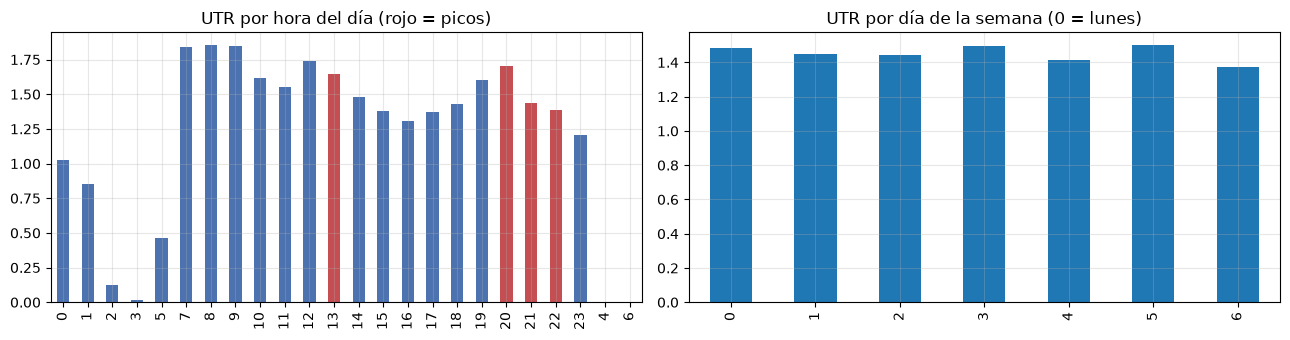

In [22]:
# 7.1 UTR agregado = Σ pedidos entregados / Σ horas conectadas
v = sh[sh['dur_ok']].merge(riders_u[['id_repartidor', 'vehicle_name', 'tasa_aceptacion']], left_on='rider_id', right_on='id_repartidor', how='left')
v['vehicle_name'] = v['vehicle_name'].fillna('sin dato')
v['acept_tramo'] = pd.cut(v['tasa_aceptacion'], TRAMOS_ACEPT, labels=ETIQ_ACEPT, include_lowest=True).astype(object).fillna('sin dato')
UTR_TOTAL = v['ped_utr'].sum() / v['horas_utr'].sum()
print(f"UTR agregado total: {UTR_TOTAL:.3f} pedidos entregados por hora conectada (Σ {v['ped_utr'].sum():,.0f} pedidos / Σ {v['horas_utr'].sum():,.0f} hs)")

# Horas conectadas por hora del día: cada turno se reparte entre las horas que cubre
d = v[['shift_id', 'inicio_turno_real', 'fin_turno_real']].copy()
d['h0'] = d['inicio_turno_real'].dt.floor('h'); d['h1'] = d['fin_turno_real'].dt.floor('h')
n_h = ((d['h1'] - d['h0']).dt.total_seconds() // 3600 + 1).astype(int)
ex = d.loc[d.index.repeat(n_h)].copy()
ex['h'] = ex['h0'] + pd.to_timedelta(ex.groupby(level=0).cumcount(), unit='h')
fin_h = ex['h'] + pd.Timedelta(hours=1)
fin_ = ex['fin_turno_real'].where(ex['fin_turno_real'] < fin_h, fin_h)
ini_ = ex['inicio_turno_real'].where(ex['inicio_turno_real'] > ex['h'], ex['h'])
ex['horas'] = (fin_ - ini_).dt.total_seconds() / 3600
print(f"Control: horas repartidas por hora {ex['horas'].sum():,.0f} vs horas de turno {v['horas_utr'].sum():,.0f}")

# Pedidos entregados dentro de un turno válido
mm = m[m['en_turno'] & m['entregado'] & m['shift_id'].isin(v['shift_id'])].copy()
print(f"Control: pedidos en el numerador {len(mm):,} vs Σ entregados de los turnos {v['ped_utr'].sum():,.0f}")
for col in ['vehicle_name', 'acept_tramo']:
    mm[col] = mm['shift_id'].map(v.set_index('shift_id')[col])

def utr_tab(num, den):
    t = pd.concat([num.rename('entregados'), den.rename('horas')], axis=1)
    t = t.fillna({'entregados': 0, 'horas': 0})
    t['UTR'] = t['entregados'] / t['horas'].where(t['horas'] > 0)
    return t
utr_hora = utr_tab(mm.groupby(mm['rider_notified_at'].dt.hour).size(), ex.groupby(ex['h'].dt.hour)['horas'].sum())
utr_dow  = utr_tab(mm.groupby(mm['rider_notified_at'].dt.dayofweek).size(), ex.groupby(ex['h'].dt.dayofweek)['horas'].sum())
utr_veh  = utr_tab(mm.groupby('vehicle_name').size(), v.groupby('vehicle_name')['horas_utr'].sum())
utr_ac   = utr_tab(mm.groupby('acept_tramo').size(), v.groupby('acept_tramo')['horas_utr'].sum()).reindex(ETIQ_ACEPT + ['sin dato']).dropna(how='all')

PICOS = sorted(utr_hora['entregados'].nlargest(4).index.tolist())      # picos = 4 horas del día con más pedidos
en_pico = utr_hora.index.isin(PICOS)
UTR_PICOS = utr_hora.loc[en_pico, 'entregados'].sum() / utr_hora.loc[en_pico, 'horas'].sum()
UTR_FUERA = utr_hora.loc[~en_pico, 'entregados'].sum() / utr_hora.loc[~en_pico, 'horas'].sum()
print(f'\nPicos de demanda (4 horas con más pedidos): {PICOS} | UTR en picos: {UTR_PICOS:.3f} | fuera de picos: {UTR_FUERA:.3f}')
print('\nUTR por hora del día:'); print(utr_hora.round(3))
print('\nUTR por día de la semana (0 = lunes):'); print(utr_dow.round(3))
print('\nUTR por vehículo:'); print(utr_veh.round(3))
print('\nUTR por tramo de tasa_aceptacion del rider:'); print(utr_ac.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
utr_hora['UTR'].plot.bar(ax=ax[0], color=['#c44e52' if h in PICOS else '#4c72b0' for h in utr_hora.index], title='UTR por hora del día (rojo = picos)')
utr_dow['UTR'].plot.bar(ax=ax[1], title='UTR por día de la semana (0 = lunes)')
plt.tight_layout(); plt.show()

In [23]:
# 7.2 Rider-día (para las correlaciones; el UTR de referencia es el agregado de 7.1)
tu['fecha'] = tu['inicio'].dt.date
hs = tu.groupby(['rider_id','fecha'])['duracion_hs'].sum().rename('horas').reset_index().rename(columns={'rider_id':'id_repartidor'})
pd_rd = pe.groupby(['id_repartidor','fecha']).agg(pedidos=('id_pedido','count'), pago=('pago_total','sum')).reset_index()
prod = pd_rd.merge(hs, on=['id_repartidor','fecha'], how='inner')
prod = prod[(prod['horas'] > .5) & (prod['horas'] <= 16)]
prod['ped_hora'] = prod['pedidos'] / prod['horas']; prod['pago_hora'] = prod['pago'] / prod['horas']
print(f'Rider-día con turno y pedidos: {len(prod):,} (de {len(pd_rd):,} rider-día con pedidos)')
print(prod[['horas','pedidos','ped_hora']].describe())
prod = prod.merge(riders_u, on='id_repartidor', how='left')
# Agregado por vehículo (Σ/Σ). El ingreso por hora se muestra como índice (total = 100), no en unidades monetarias.
pv = prod.groupby('vehicle_name').agg(rider_dias=('pedidos', 'size'), pedidos=('pedidos', 'sum'), horas=('horas', 'sum'), pago=('pago', 'sum'))
pv['UTR_agregado'] = pv['pedidos'] / pv['horas']
pv['ingreso_hora_indice'] = (pv['pago'] / pv['horas']) / (prod['pago'].sum() / prod['horas'].sum()) * 100
print(f"\nUTR agregado rider-día: {prod['pedidos'].sum() / prod['horas'].sum():.3f}")
print(pv[['rider_dias', 'UTR_agregado', 'ingreso_hora_indice']].round(3))
print(prod[['horas','pedidos','ped_hora','pago_hora','tasa_aceptacion','avg_batch','tenure_in_weeks']].corr(method='spearman').round(2))

Rider-día con turno y pedidos: 31,520 (de 45,244 rider-día con pedidos)
          horas   pedidos  ped_hora
count 31,520.00 31,520.00 31,520.00
mean       6.08      9.06      1.49
std        2.73      5.75      0.69
min        0.51      1.00      0.07
25%        3.85      5.00      1.01
50%        5.24      8.00      1.47
75%        8.10     12.00      1.93
max       15.99     42.00     14.23

UTR agregado rider-día: 1.489
              rider_dias  UTR_agregado  ingreso_hora_indice
vehicle_name                                               
Automovil             97          0.91                58.85
Bicicleta          19007          1.45                90.83
CAFE - Bici          412          1.56                98.92
CAFE - Moto           59          1.52               112.42
Motocicleta        11945          1.54               113.25
                 horas  pedidos  ped_hora  pago_hora  tasa_aceptacion  \
horas             1.00     0.69      0.02       0.05            -0.04   
pedidos

## 8. Relación entre turnos, riders y pedidos
_Preguntas: ¿las tres tablas se pueden cruzar (claves, período)? ¿Qué parte de los pedidos se entrega dentro de un turno registrado? ¿Cuánto del turno se usa en pedidos? ¿Qué rider cumple, llega tarde o no se conecta, y cómo se relaciona con su perfil (vehículo, antigüedad, aceptación)? Relacionada con H1, H2, H3, H6 y H7._

Claves: `pedidos.id_repartidor` = `riders.id_repartidor` = `turnos.rider_id`. Un pedido se asigna a un turno si el rider tiene un turno con `inicio_turno_real <= rider_notified_at <= fin_turno_real`.

In [24]:
# 8.1 Integridad de claves y período en común (la asignación pedido -> turno se construye en 7.0)
S_ped, S_tur, S_rid = set(ped_ok['id_repartidor']), set(tr['rider_id']), set(riders['id_repartidor'])
print(pd.DataFrame({
    'riders únicos': [len(S_ped), len(S_tur), len(S_rid)],
    'están en riders': [len(S_ped & S_rid), len(S_tur & S_rid), len(S_rid)],
    'están en turnos': [len(S_ped & S_tur), len(S_tur), len(S_rid & S_tur)],
    'están en pedidos': [len(S_ped), len(S_tur & S_ped), len(S_rid & S_ped)]}, index=['pedidos', 'turnos', 'riders']))
print(f"\nPedidos : {ped_ok['rider_notified_at'].min():%Y-%m-%d} -> {ped_ok['rider_notified_at'].max():%Y-%m-%d}")
print(f"Turnos  : {tr['inicio_turno_planificado'].min():%Y-%m-%d} -> {tr['fin_turno_planificado'].max():%Y-%m-%d}")
print(f'Período en común (se usa en toda la sección): {DESDE:%Y-%m-%d} -> {HASTA:%Y-%m-%d}')

         riders únicos  están en riders  están en turnos  están en pedidos
pedidos           5288             5206             3285              5288
turnos            3848             3462             3848              3285
riders            8290             8290             3462              5206

Pedidos : 2024-04-30 -> 2024-05-31
Turnos  : 2024-04-30 -> 2024-06-01
Período en común (se usa en toda la sección): 2024-04-30 -> 2024-05-31


                                         pedidos   pct
causa                                                 
dentro de un turno                        288268 87.57
rider con turnos, pero fuera de horario    23225  7.06
rider sin ningún turno                     17703  5.38


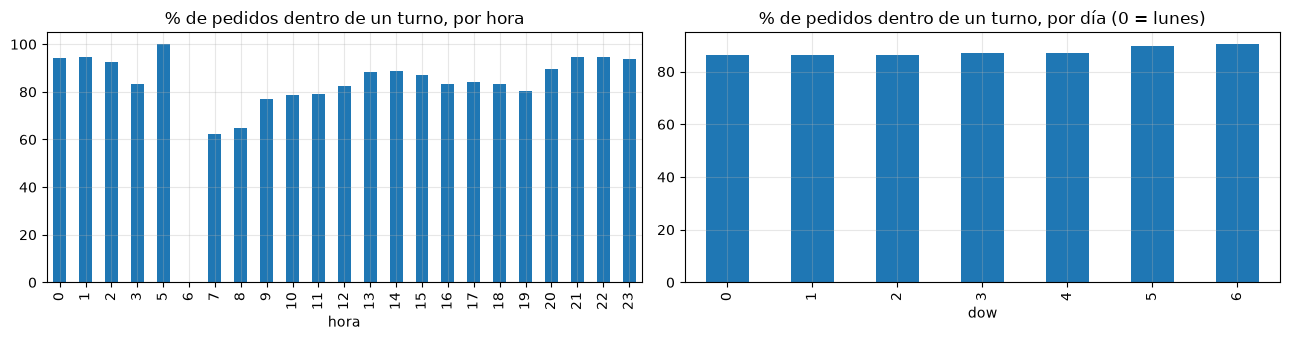

Mediana t_aceptacion (min):
en_turno
False   0.21
True    0.17
Name: t_aceptacion, dtype: float64


In [25]:
# 8.2 Pedido -> turno: ¿cuántos pedidos se entregan dentro de un turno registrado? (asignación hecha en 7.0)
print(m['causa'].value_counts().to_frame('pedidos').assign(pct=lambda d: d['pedidos'] / d['pedidos'].sum() * 100))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
m.groupby('hora')['en_turno'].mean().mul(100).plot.bar(ax=ax[0], title='% de pedidos dentro de un turno, por hora')
m.groupby('dow')['en_turno'].mean().mul(100).plot.bar(ax=ax[1], title='% de pedidos dentro de un turno, por día (0 = lunes)')
plt.tight_layout(); plt.show()
print('Mediana t_aceptacion (min):'); print(m.groupby('en_turno')['t_aceptacion'].median())

Turnos planificados: 78,173 | no conectados (sin horario real): 27,067 (34.6%)
Turnos conectados sin ningún pedido: 4,018 (7.9%)
UTR agregado (7.1): 1.452 pedidos entregados por hora conectada

Pedidos por turno conectado:
count   51,106.00
mean         5.64
std          3.51
min          0.00
25%          3.00
50%          6.00
75%          8.00
max         26.00
Name: pedidos, dtype: float64

Puntualidad (min) y duración (hs); ped_hora es la distribución por turno, NO el UTR agregado:
                      count  mean   std     min     5%  50%    95%       max
demora_inicio_min 51,106.00 27.55 57.32  -29.87 -21.77 1.52 162.45    357.67
dif_fin_min       51,106.00  3.01 72.20 -299.60   0.00 0.20  23.81 15,855.53
dur_plan_hs       51,106.00  4.28  1.07    0.00   3.50 4.00   6.00     17.50
dur_real_hs       51,106.00  3.87  1.73    0.00   1.39 3.87   5.78    265.26
ped_hora          50,247.00  1.45  0.77    0.00   0.00 1.48   2.66      6.61


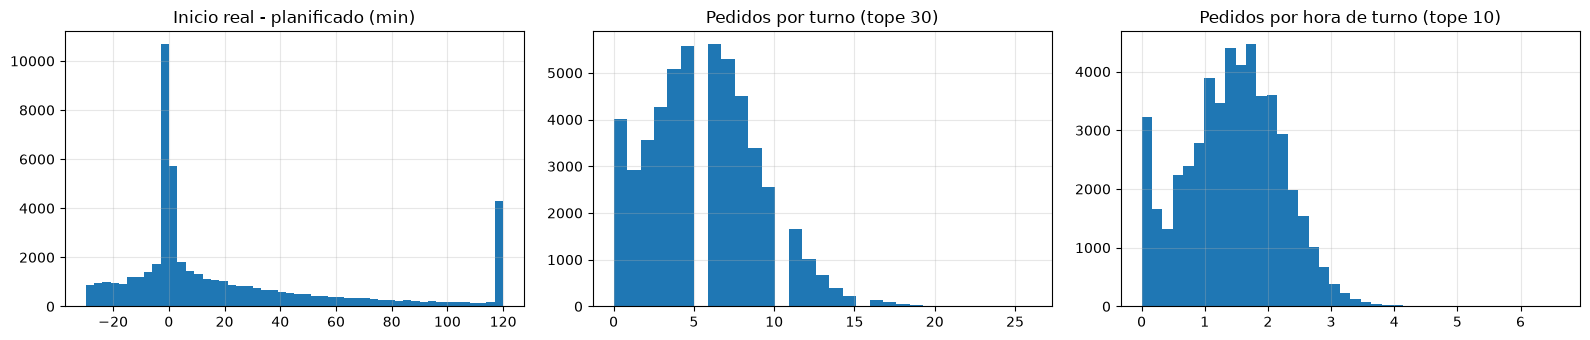

Spearman duración real / demora de inicio vs pedidos por turno:
dur_real_hs          0.50
demora_inicio_min   -0.21
pedidos              1.00
Name: pedidos, dtype: float64


In [26]:
# 8.3 Turno -> pedidos: cumplimiento, puntualidad y utilización
con = sh[sh['conectado']]
print(f"Turnos planificados: {len(sh):,} | no conectados (sin horario real): {(~sh['conectado']).sum():,} ({(~sh['conectado']).mean():.1%})")
print(f"Turnos conectados sin ningún pedido: {(con['pedidos'] == 0).sum():,} ({(con['pedidos'] == 0).mean():.1%})")
print(f'UTR agregado (7.1): {UTR_TOTAL:.3f} pedidos entregados por hora conectada')
print('\nPedidos por turno conectado:'); print(con['pedidos'].describe())
print('\nPuntualidad (min) y duración (hs); ped_hora es la distribución por turno, NO el UTR agregado:')
print(con[['demora_inicio_min', 'dif_fin_min', 'dur_plan_hs', 'dur_real_hs', 'ped_hora']].describe(percentiles=[.05, .5, .95]).T)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
con['demora_inicio_min'].clip(-30, 120).hist(ax=ax[0], bins=50); ax[0].set_title('Inicio real - planificado (min)')
con['pedidos'].clip(upper=30).hist(ax=ax[1], bins=31); ax[1].set_title('Pedidos por turno (tope 30)')
con['ped_hora'].clip(upper=10).hist(ax=ax[2], bins=40); ax[2].set_title('Pedidos por hora de turno (tope 10)')
plt.tight_layout(); plt.show()
print('Spearman duración real / demora de inicio vs pedidos por turno:')
print(con[['dur_real_hs', 'demora_inicio_min', 'pedidos']].corr(method='spearman').round(2)['pedidos'])

In [27]:
# 8.4 Perfil del rider vs cumplimiento y uso del turno
rd = sh.groupby('rider_id').agg(turnos=('shift_id', 'count'), no_show=('conectado', lambda s: 1 - s.mean()),
                                horas=('horas_utr', 'sum'), demora_med=('demora_inicio_min', 'median'),
                                ped_en_turno=('ped_utr', 'sum'))
rd['ped_hora'] = rd['ped_en_turno'] / rd['horas'].where(rd['horas'] > 1)      # ratio por rider: solo para correlaciones
pt = m.groupby('id_repartidor').agg(ped_total=('id_pedido', 'count'), pct_fuera_turno=('en_turno', lambda s: 1 - s.mean()))
rd = rd.join(pt, how='outer').join(riders_u.set_index('id_repartidor'))
rd[['turnos', 'ped_en_turno', 'ped_total']] = rd[['turnos', 'ped_en_turno', 'ped_total']].fillna(0)
print('Riders con turnos y con pedidos:', ((rd['turnos'] > 0) & (rd['ped_total'] > 0)).sum(), '| solo turnos:', ((rd['turnos'] > 0) & (rd['ped_total'] == 0)).sum(),
      '| solo pedidos:', ((rd['turnos'] == 0) & (rd['ped_total'] > 0)).sum())
act = rd[(rd['turnos'] >= 3) & (rd['ped_total'] >= 10)]
cols = ['turnos', 'no_show', 'demora_med', 'ped_hora', 'pct_fuera_turno', 'tasa_aceptacion', 'avg_batch', 'tenure_in_weeks']
print(f'\nCorrelación de Spearman rider-nivel ({len(act):,} riders con >= 3 turnos y >= 10 pedidos):'); print(act[cols].corr(method='spearman').round(2))

def resumen(df, k):
    t = df.groupby(k, observed=True).agg(riders=('turnos', 'size'), no_show=('no_show', 'median'), demora_med=('demora_med', 'median'),
                                         pct_fuera_turno=('pct_fuera_turno', 'median'), ped=('ped_en_turno', 'sum'), horas=('horas', 'sum'))
    t['UTR_agregado'] = t['ped'] / t['horas']
    return t[['riders', 'no_show', 'demora_med', 'pct_fuera_turno', 'UTR_agregado']]
print('\nPor vehículo (UTR agregado = Σ pedidos / Σ horas del grupo):'); print(resumen(act, 'vehicle_name'))
act = act.assign(tenure_grupo=pd.cut(act['tenure_in_weeks'], [-1, 4, 12, 26, 52, 1e9], labels=['<=4 sem', '5-12', '13-26', '27-52', '>52']))
print('\nPor antigüedad:'); print(resumen(act, 'tenure_grupo'))

Riders con turnos y con pedidos: 3281 | solo turnos: 557 | solo pedidos: 2007

Correlación de Spearman rider-nivel (2,342 riders con >= 3 turnos y >= 10 pedidos):
                 turnos  no_show  demora_med  ped_hora  pct_fuera_turno  \
turnos             1.00     0.13        0.06      0.17            -0.42   
no_show            0.13     1.00        0.14     -0.12            -0.03   
demora_med         0.06     0.14        1.00     -0.14            -0.36   
ped_hora           0.17    -0.12       -0.14      1.00            -0.13   
pct_fuera_turno   -0.42    -0.03       -0.36     -0.13             1.00   
tasa_aceptacion   -0.16    -0.07       -0.18      0.33             0.09   
avg_batch         -0.19     0.37        0.33     -0.42            -0.04   
tenure_in_weeks    0.31    -0.03       -0.05      0.17            -0.06   

                 tasa_aceptacion  avg_batch  tenure_in_weeks  
turnos                     -0.16      -0.19             0.31  
no_show                    -0.07   

/var/folders/6z/2nkwfpvj5vdbpmc404rhvrsh0000gn/T/ipykernel_28225/2445701041.py:10: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  of = pd.concat([riders_por_hora(sh, 'inicio_turno_planificado', 'fin_turno_planificado').rename('planificados'),


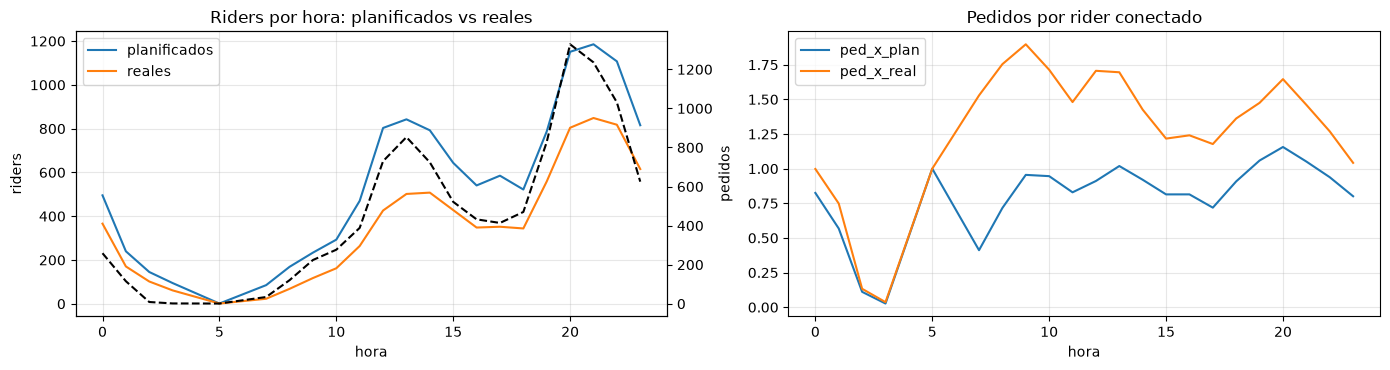

Spearman horario con pedidos:
planificados   0.94
reales         0.93
dtype: float64
Cumplimiento de la oferta (reales / planificados), promedio: 62.5%


In [28]:
# 8.5 Oferta planificada vs oferta real vs demanda, por hora del día
def riders_por_hora(df, ini, fin):
    d = df.dropna(subset=[ini, fin]).copy()
    d['h0'], d['h1'] = d[ini].dt.floor('h'), d[fin].dt.floor('h')
    d = d[(d['h1'] >= d['h0']) & ((d[fin] - d[ini]).dt.total_seconds() <= 24 * 3600)]
    r = d.loc[d.index.repeat(((d['h1'] - d['h0']).dt.total_seconds() // 3600 + 1).astype(int))].copy()
    r['h'] = r['h0'] + pd.to_timedelta(r.groupby(level=0).cumcount(), unit='h')
    return r.groupby('h')['rider_id'].nunique()

of = pd.concat([riders_por_hora(sh, 'inicio_turno_planificado', 'fin_turno_planificado').rename('planificados'),
                riders_por_hora(sh, 'inicio_turno_real', 'fin_turno_real').rename('reales'),
                m.groupby(m['rider_notified_at'].dt.floor('h'))['id_pedido'].count().rename('pedidos')], axis=1).dropna()
of['ped_x_plan'] = of['pedidos'] / of['planificados']; of['ped_x_real'] = of['pedidos'] / of['reales']
of['hora'] = of.index.hour
g = of.groupby('hora')[['planificados', 'reales', 'pedidos', 'ped_x_plan', 'ped_x_real']].mean()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
g[['planificados', 'reales']].plot(ax=ax[0], title='Riders por hora: planificados vs reales'); g['pedidos'].plot(ax=ax[0], secondary_y=True, color='k', ls='--', label='pedidos')
ax[0].right_ax.set_ylabel('pedidos'); ax[0].set_ylabel('riders')
g[['ped_x_plan', 'ped_x_real']].plot(ax=ax[1], title='Pedidos por rider conectado')
plt.tight_layout(); plt.show()
print('Spearman horario con pedidos:'); print(of[['planificados', 'reales']].corrwith(of['pedidos'], method='spearman').round(2))
print(f"Cumplimiento de la oferta (reales / planificados), promedio: {(of['reales'] / of['planificados']).mean():.1%}")

## 9. Un-dispatch: tasas oficiales y relación con el nivel de servicio
_Hipótesis: H8, H9, H10._

Las tasas se calculan con las definiciones de la profesora **sobre todas las filas de `pedidos`** (una por transición), no sobre `ped`:
- **Tasa de rechazo** (pre-aceptación) = Σ `pre_accept_undispatch` / Σ notificaciones totales.
- **Tasa de un-dispatch post-aceptación** = Σ `post_accept_undispatchs` / Σ órdenes aceptadas (filas `accepted`).

*Notificaciones totales* no está definido en la consigna: en 9.1 se comparan varios denominadores candidatos contra el ~30% de rechazo (= 100% − 70% de aceptación) y la definición final queda en **revisar**. En los análisis por pedido (9.3) `ped` ya trae el un-dispatch sumado por pedido (sección 2). La reconstrucción por reasignación (más de un `accepted`) queda en 9.4 como control cruzado.

In [29]:
# 9.1 ¿Dónde están los un-dispatch? Denominadores candidatos para la tasa de rechazo
print(pedidos.groupby('transicion')[cols_u].agg(['sum', 'max']))
q = pedidos['transicion'] == 'queued'
print(f"\nFilas queued: {int(q.sum()):,} | con exactamente 1 un-dispatch (pre + post = 1): {(pedidos.loc[q, cols_u].sum(axis=1) == 1).mean():.1%}"
      f" | filas no-queued con algún un-dispatch: {int((pedidos.loc[~q, cols_u].sum(axis=1) > 0).sum())}")
SUM_PRE, SUM_POST = int(pedidos[cols_u[0]].sum()), int(pedidos[cols_u[1]].sum())
N_ACEPT = int((pedidos['transicion'] == 'accepted').sum()); N_QUEUED = int(q.sum())
N_FILAS = len(pedidos); N_PED = pedidos['id_pedido'].nunique()
print(f'Σ pre = {SUM_PRE:,} | Σ post = {SUM_POST:,} | filas accepted = {N_ACEPT:,} | filas queued = {N_QUEUED:,} | pedidos únicos = {N_PED:,} | filas = {N_FILAS:,}')

cand = pd.DataFrame([
    ('A', 'aceptaciones (filas accepted) + Σ pre', N_ACEPT + SUM_PRE),
    ('B', 'filas accepted + filas queued', N_ACEPT + N_QUEUED),
    ('C', 'pedidos únicos + Σ pre', N_PED + SUM_PRE),
    ('D', 'pedidos únicos', N_PED),
    ('E', 'filas totales de `pedidos`', N_FILAS)], columns=['cod', 'denominador', 'valor']).set_index('cod')
cand['tasa_rechazo_%'] = SUM_PRE / cand['valor'] * 100
cand['aceptacion_implicita_%'] = 100 - cand['tasa_rechazo_%']
cand['dif_vs_30pp'] = (cand['tasa_rechazo_%'] - 30).abs()
print('\nTasa de rechazo según el denominador (consigna: ~30%):'); print(cand.round(2))
MAS_CERCANO = cand['dif_vs_30pp'].idxmin()
print(f"\nDenominador más cercano al 30%: {MAS_CERCANO} ({cand.loc[MAS_CERCANO, 'denominador']}) -> {cand.loc[MAS_CERCANO, 'tasa_rechazo_%']:.2f}%")
DEN_TRABAJO = 'A'
print(f"Definición de trabajo en 9.2: {DEN_TRABAJO} (cada notificación termina en aceptación o en rechazo). DEFINICIÓN FINAL: REVISAR con la profesora.")

# Comparación con tasa_aceptacion de la base de riders
acp = pedidos[pedidos['transicion'] == 'accepted'].groupby('transicion_id_repartidor').size().rename('aceptadas')
rr = riders_u.set_index('id_repartidor')[['tasa_aceptacion']].join(acp, how='left').dropna(subset=['tasa_aceptacion'])
rw = rr[rr['aceptadas'].fillna(0) > 0]
print('\nComparación con tasa_aceptacion (base de riders):')
print(pd.Series({'promedio simple (todos los riders)': rr['tasa_aceptacion'].mean() * 100,
                 'ponderado por órdenes aceptadas (riders con aceptaciones)': np.average(rw['tasa_aceptacion'], weights=rw['aceptadas']) * 100,
                 f"1 - rechazo con denominador {DEN_TRABAJO}": cand.loc[DEN_TRABAJO, 'aceptacion_implicita_%'],
                 'consigna': 70.0}).round(2).to_frame('aceptación_%'))

            pre_accept_undispatch     post_accept_undispatchs    
                              sum max                     sum max
transicion                                                       
accepted                        0   0                       0   0
near_pickup                     0   0                       0   0
picked_up                       0   0                       0   0
queued                     184476   1                   17000   1

Filas queued: 201,476 | con exactamente 1 un-dispatch (pre + post = 1): 100.0% | filas no-queued con algún un-dispatch: 0
Σ pre = 184,476 | Σ post = 17,000 | filas accepted = 346,554 | filas queued = 201,476 | pedidos únicos = 329,196 | filas = 1,217,343

Tasa de rechazo según el denominador (consigna: ~30%):
                               denominador    valor  tasa_rechazo_%  \
cod                                                                   
A    aceptaciones (filas accepted) + Σ pre   531030           34.74   
B            

TOTAL (consigna: rechazo ~30%, post-aceptación ~2%):
       aceptadas     pre   post  notificaciones  rechazo_%  post_aceptacion_%
total     346554  184476  17000          531030      34.74               4.91

Por hora del día:
      aceptadas    pre  post  rechazo_%  post_aceptacion_%
hora                                                      
0          8700   6398   670      42.38               7.70
1          3785   2394   209      38.74               5.52
2           353    614    77      63.50              21.81
3            11     15     5      57.69              45.45
5             1      0     0       0.00               0.00
6             1      0     0       0.00               0.00
7          1097    499    30      31.27               2.73
8          3863   1781   123      31.56               3.18
9          7191   3205   247      30.83               3.43
10         8890   3995   306      31.01               3.44
11        12510   5080   456      28.88               3.65
12   

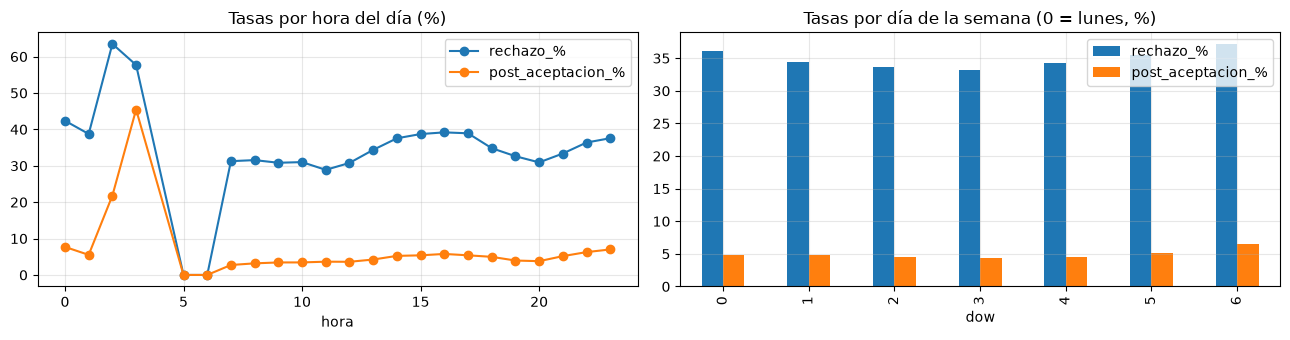

In [30]:
# 9.2 Tasas oficiales por segmento (el un-dispatch se atribuye al rider de la fila queued: transicion_id_repartidor)
ev = pedidos[['id_pedido', 'transicion', 'transicion_id_repartidor', 'rider_notified_at'] + cols_u].copy()
ev['es_acept'] = (ev['transicion'] == 'accepted').astype(int)
ev['hora'] = ev['rider_notified_at'].dt.hour; ev['dow'] = ev['rider_notified_at'].dt.dayofweek
ev = ev.merge(riders_u[['id_repartidor', 'vehicle_name', 'tenure_in_weeks', 'tasa_aceptacion']], left_on='transicion_id_repartidor', right_on='id_repartidor', how='left')
ev['vehiculo'] = ev['vehicle_name'].fillna('sin dato')
ev['antiguedad'] = pd.cut(ev['tenure_in_weeks'], [-1, 4, 12, 26, 52, 1e9], labels=['<=4 sem', '5-12', '13-26', '27-52', '>52']).astype(object).fillna('sin dato')
ev['tramo_aceptacion'] = pd.cut(ev['tasa_aceptacion'], TRAMOS_ACEPT, labels=ETIQ_ACEPT, include_lowest=True).astype(object).fillna('sin dato')

def tasas(df, by=None):
    g = df.groupby(by if by else lambda _: 'total', observed=True).agg(aceptadas=('es_acept', 'sum'), pre=(cols_u[0], 'sum'), post=(cols_u[1], 'sum'))
    g['notificaciones'] = g['aceptadas'] + g['pre']                  # denominador A (revisar)
    g['rechazo_%'] = g['pre'] / g['notificaciones'] * 100
    g['post_aceptacion_%'] = g['post'] / g['aceptadas'] * 100
    return g
tot = tasas(ev)
TASA_RECHAZO, TASA_POST = tot.loc['total', 'rechazo_%'], tot.loc['total', 'post_aceptacion_%']
print('TOTAL (consigna: rechazo ~30%, post-aceptación ~2%):'); print(tot.round(2))
for nombre, k in [('hora del día', 'hora'), ('día de la semana (0 = lunes)', 'dow'), ('vehículo', 'vehiculo'), ('antigüedad del rider', 'antiguedad'), ('tramo de tasa_aceptacion del rider', 'tramo_aceptacion')]:
    print(f'\nPor {nombre}:'); print(tasas(ev, k)[['aceptadas', 'pre', 'post', 'rechazo_%', 'post_aceptacion_%']].round(2))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
th, td = tasas(ev, 'hora'), tasas(ev, 'dow')
th[['rechazo_%', 'post_aceptacion_%']].plot(ax=ax[0], marker='o', title='Tasas por hora del día (%)')
td[['rechazo_%', 'post_aceptacion_%']].plot.bar(ax=ax[1], title='Tasas por día de la semana (0 = lunes, %)')
plt.tight_layout(); plt.show()

Pedidos con >= 1 pre-aceptación: 26.62% | con >= 1 post-aceptación: 4.40% | cancelados: 0.49%

pre_accept_undispatch (3 = 3 o más) — tiempos en minutos sobre pedidos entregados; cancelados sobre todos los pedidos
   pedidos  t_aceptacion  t_espera_local  t_total  t_total_vs_hora  \
n                                                                    
0   231883          0.16            4.19    16.70            -0.32   
1    47270          0.19            3.25    17.39             0.40   
2    16717          0.20            2.89    18.02             1.10   
3    18671          0.20            2.70    18.89             2.03   

   cancelados_%  
n                
0          0.48  
1          0.46  
2          0.40  
3          0.73  

post_accept_undispatchs (2 = 2 o más) — tiempos en minutos sobre pedidos entregados; cancelados sobre todos los pedidos
   pedidos  t_aceptacion  t_espera_local  t_total  t_total_vs_hora  \
n                                                                  

                         pre_accept_undispatch  post_accept_undispatchs  \
pre_accept_undispatch                     1.00                     0.17   
post_accept_undispatchs                   0.17                     1.00   

                         t_aceptacion  t_a_local  t_espera_local  t_total  \
pre_accept_undispatch            0.09       0.07           -0.14     0.09   
post_accept_undispatchs          0.03      -0.01           -0.04     0.00   

                         pu_distance  do_distance  pago_base  pago_incentivos  \
pre_accept_undispatch           0.10         0.22       0.16             0.02   
post_accept_undispatchs         0.00         0.04       0.04             0.02   

                         pago_total  
pre_accept_undispatch          0.15  
post_accept_undispatchs        0.04  

Pago medio por pedido según rechazos previos (índice, 0 rechazos = 100; la distancia también varía, ver Spearman):
   pago_base  pago_incentivos  pago_total
n                         

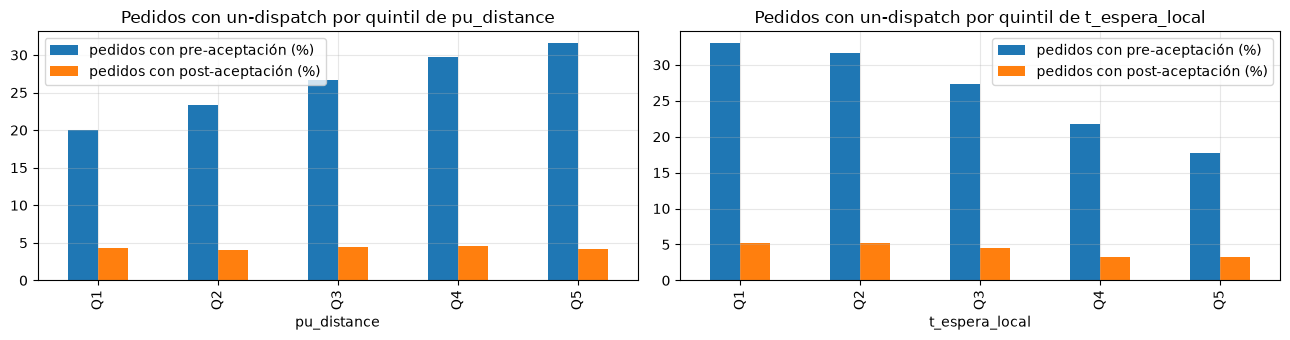

In [31]:
# 9.3 Un-dispatch por pedido vs nivel de servicio (H9) y vs distancia / espera en el local (H10)
pe['t_total_vs_hora'] = pe['t_total'] - pe.groupby('hora')['t_total'].transform('median')   # controla el efecto de la hora
ped['cancelado'] = (ped['order_status'] == 'cancelled')
print(f"Pedidos con >= 1 pre-aceptación: {(ped[cols_u[0]] > 0).mean():.2%} | con >= 1 post-aceptación: {(ped[cols_u[1]] > 0).mean():.2%} | cancelados: {ped['cancelado'].mean():.2%}")
for v_, tope in [(cols_u[0], 3), (cols_u[1], 2)]:
    a = pe.assign(n=pe[v_].clip(upper=tope)).groupby('n').agg(pedidos=('id_pedido', 'count'), t_aceptacion=('t_aceptacion', 'median'),
          t_espera_local=('t_espera_local', 'median'), t_total=('t_total', 'median'), t_total_vs_hora=('t_total_vs_hora', 'median'))
    a['cancelados_%'] = ped.assign(n=ped[v_].clip(upper=tope)).groupby('n')['cancelado'].mean() * 100
    print(f'\n{v_} ({tope} = {tope} o más) — tiempos en minutos sobre pedidos entregados; cancelados sobre todos los pedidos'); print(a.round(2))

cc = cols_u + ['t_aceptacion', 't_a_local', 't_espera_local', 't_total', 'pu_distance', 'do_distance', 'pago_base', 'pago_incentivos', 'pago_total']
print('\nSpearman del un-dispatch con tiempos, distancias y pago:'); print(pe[cc].corr(method='spearman').loc[cols_u].round(3))
pi = pe.assign(n=pe[cols_u[0]].clip(upper=3)).groupby('n')[['pago_base', 'pago_incentivos', 'pago_total']].mean()
print('\nPago medio por pedido según rechazos previos (índice, 0 rechazos = 100; la distancia también varía, ver Spearman):'); print((pi / pi.iloc[0] * 100).round(1))
print(f"\nEspera en el local / tiempo total (Σ/Σ): {pe['t_espera_local'].sum() / pe['t_total'].sum():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for a_, v_ in zip(ax, ['pu_distance', 't_espera_local']):
    qq = pd.qcut(pe[v_].rank(method='first'), 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
    pd.DataFrame({'pedidos con pre-aceptación (%)': (pe[cols_u[0]] > 0).groupby(qq, observed=True).mean() * 100,
                  'pedidos con post-aceptación (%)': (pe[cols_u[1]] > 0).groupby(qq, observed=True).mean() * 100}).plot.bar(ax=a_, title=f'Pedidos con un-dispatch por quintil de {v_}')
    print(f'\n{v_} por quintil:'); print(pd.DataFrame({'pre_%': (pe[cols_u[0]] > 0).groupby(qq, observed=True).mean() * 100, 'post_%': (pe[cols_u[1]] > 0).groupby(qq, observed=True).mean() * 100}).round(2))
plt.tight_layout(); plt.show()

In [32]:
# 9.4 Control cruzado: reconstrucción por reasignación (más de un 'accepted' / cambio de rider aceptante) vs tasa oficial
pedidos['es_acept'] = (pedidos['transicion'] == 'accepted').astype(int)
acc = pedidos[pedidos['es_acept'] == 1]
po = pd.DataFrame({'n_acept': acc.groupby('id_pedido').size(), 'n_riders_acept': acc.groupby('id_pedido')['transicion_id_repartidor'].nunique(),
                   'primer_acept': acc.groupby('id_pedido')['creacion_transicion'].min()})
po['reasignado'] = (po['n_acept'] > 1) | (po['n_riders_acept'] > 1)
rp = ped.set_index('id_pedido').join(po)
rp['reasignado'] = rp['reasignado'].fillna(False).astype(bool)
rp['entregado_ok'] = rp['entregado'] & (rp[TIEMPOS] >= 0).all(axis=1)
rp['min_perdidos'] = ((rp['rider_accepted_at'] - rp['primer_acept']).dt.total_seconds() / 60).clip(lower=0)

reasig_ev = int((po['n_acept'] - 1).sum())          # aceptaciones "de más" = reasignaciones
tasa_recon = reasig_ev / N_ACEPT * 100
print(f"Un-dispatch post-aceptación oficial (Σ post): {SUM_POST:,} -> {TASA_POST:.2f}% de las aceptaciones")
print(f"Reconstruido (Σ aceptaciones - 1 por pedido): {reasig_ev:,} -> {tasa_recon:.2f}% | coinciden en {1 - abs(reasig_ev - SUM_POST) / SUM_POST:.1%} del volumen")
post_pos = rp[cols_u[1]] > 0
print(f"\nPedidos reasignados: {int(rp['reasignado'].sum()):,} | con post-aceptación > 0: {int(post_pos.sum()):,} | ambos: {int((rp['reasignado'] & post_pos).sum()):,}")
print('Coincidencia pedido a pedido (reasignado == post > 0):', f"{(rp['reasignado'] == post_pos).mean():.2%}")
print(pd.crosstab(rp['reasignado'], post_pos, margins=True).rename(index={True: 'reasignado', False: 'no reasignado'}, columns={True: 'post > 0', False: 'post = 0'}))

# Por rider: abandonos reconstruidos (aceptó y no fue el rider final) vs post-aceptación oficial (fila queued con post = 1)
acc = acc.assign(abandono=acc['transicion_id_repartidor'] != acc['id_repartidor'])
cr = pd.DataFrame({'aceptadas': acc.groupby('transicion_id_repartidor').size(), 'abandonos_recon': acc.groupby('transicion_id_repartidor')['abandono'].sum(),
                   'post_oficial': pedidos.groupby('transicion_id_repartidor')[cols_u[1]].sum()}).fillna(0)
cr = cr[cr['aceptadas'] >= 20]
print(f"\nPor rider ({len(cr):,} riders con >= 20 aceptaciones): Spearman abandonos reconstruidos vs post-aceptación oficial = {cr[['abandonos_recon', 'post_oficial']].corr(method='spearman').iloc[0, 1]:.2f}")
print(f"Tasa global de abandono reconstruida (aceptó y no es el rider final): {cr['abandonos_recon'].sum() / cr['aceptadas'].sum():.2%} | oficial: {cr['post_oficial'].sum() / cr['aceptadas'].sum():.2%}")

# Costo de la reasignación en nivel de servicio (insumo de 10.3)
ent = rp[rp['entregado_ok']]
cmp_ = rp.groupby('reasignado').agg(pedidos=('rider_notified_at', 'size'), cancelados=('order_status', lambda s: (s == 'cancelled').mean()))
cmp_ = cmp_.join(ent.groupby('reasignado')[['t_aceptacion', 't_a_local', 't_espera_local', 't_viaje', 't_total']].median())
print('\nNivel de servicio según reasignación:'); print(cmp_.round(3))
re = rp[rp['reasignado']]
print('\nMinutos entre la primera aceptación y la aceptación final (pedidos reasignados):'); print(re['min_perdidos'].describe(percentiles=[.5, .9]).round(2))
MIN_PERDIDOS_REASIG = re['min_perdidos'].mean()
CANC_REASIG, CANC_NO = cmp_.loc[True, 'cancelados'], cmp_.loc[False, 'cancelados']

Un-dispatch post-aceptación oficial (Σ post): 17,000 -> 4.91% de las aceptaciones
Reconstruido (Σ aceptaciones - 1 por pedido): 17,358 -> 5.01% | coinciden en 97.9% del volumen

Pedidos reasignados: 14,717 | con post-aceptación > 0: 14,488 | ambos: 14,488
Coincidencia pedido a pedido (reasignado == post > 0): 99.93%
post_accept_undispatchs  post = 0  post > 0     All
reasignado                                         
no reasignado              314479         0  314479
reasignado                    229     14488   14717
All                        314708     14488  329196

Por rider (2,408 riders con >= 20 aceptaciones): Spearman abandonos reconstruidos vs post-aceptación oficial = 1.00
Tasa global de abandono reconstruida (aceptó y no es el rider final): 4.94% | oficial: 4.84%

Nivel de servicio según reasignación:
            pedidos  cancelados  t_aceptacion  t_a_local  t_espera_local  \
reasignado                                                                 
False        314479  

## 10. Escenarios de impacto (nivel de servicio, UTR y CPO)
_Hipótesis: H11._

Los valores de partida de la consigna (aceptación ~70%, un-dispatch ~2%) y los medidos en los datos se combinan con **parámetros de sensibilidad**. Por la transformación de los datos, **todo se expresa en % o en minutos** (no hay montos). Lo que no se puede medir con estos datos (minutos que suma cada oferta no aceptada, costo total por orden) queda como parámetro a **revisar**: las tablas son análisis de sensibilidad, no estimaciones puntuales.

In [33]:
# 10.1 Aceptación -> rechazos por orden -> Delivery Time (minutos y % del Delivery Time mediano)
P_ACT = 0.70                       # consigna
OBJETIVOS = [0.75, 0.80, 0.85, 0.90]
MIN_POR_RECHAZO = [0.5, 1, 2, 3]   # SENSIBILIDAD (no medido): minutos que suma a la orden cada oferta no aceptada. Revisar
mediana_total = ent['t_total'].median()

esc = pd.DataFrame({'aceptacion_%': np.array([P_ACT] + OBJETIVOS) * 100})
esc['rechazos_por_orden'] = 1 / (esc['aceptacion_%'] / 100) - 1         # supuesto: ofertas independientes, una a la vez
esc['reduccion_rechazos_%'] = (1 - esc['rechazos_por_orden'] / esc.loc[0, 'rechazos_por_orden']) * 100
for m_ in MIN_POR_RECHAZO:
    esc[f'min/orden (x{m_})'] = (esc.loc[0, 'rechazos_por_orden'] - esc['rechazos_por_orden']) * m_
    esc[f'% DT (x{m_})'] = esc[f'min/orden (x{m_})'] / mediana_total * 100
print(f'Delivery Time mediano observado: {mediana_total:.1f} min (DT = tiempo desde la notificación hasta la entrega)')
print(f"Aceptación implícita medida con los datos (denominador {DEN_TRABAJO}): {100 - TASA_RECHAZO:.1f}% (consigna: 70%). REVISAR la definición.")
print(esc.round(3).to_string(index=False))

Delivery Time mediano observado: 17.3 min (DT = tiempo desde la notificación hasta la entrega)
Aceptación implícita medida con los datos (denominador A): 65.3% (consigna: 70%). REVISAR la definición.
 aceptacion_%  rechazos_por_orden  reduccion_rechazos_%  min/orden (x0.5)  % DT (x0.5)  min/orden (x1)  % DT (x1)  min/orden (x2)  % DT (x2)  min/orden (x3)  % DT (x3)
        70.00                0.43                  0.00              0.00         0.00            0.00       0.00            0.00       0.00            0.00       0.00
        75.00                0.33                 22.22              0.05         0.28            0.10       0.55            0.19       1.10            0.29       1.65
        80.00                0.25                 41.67              0.09         0.52            0.18       1.03            0.36       2.07            0.54       3.10
        85.00                0.18                 58.82              0.13         0.73            0.25       1.46            0.5

In [34]:
# 10.2 Aceptación -> UTR -> CPO (asociación entre riders; usar como cota, no como efecto causal)
d = act.dropna(subset=['tasa_aceptacion', 'ped_hora']).copy()
d['ped_hora'] = d['ped_hora'].clip(upper=d['ped_hora'].quantile(.99))
pend, ord_ = np.polyfit(d['tasa_aceptacion'], d['ped_hora'], 1)
UTR0 = UTR_TOTAL                    # UTR agregado (7.1)
print(f'Pendiente rider-nivel: +{pend * 0.10:.3f} pedidos/hora por cada +10 pp de tasa_aceptacion ({len(d):,} riders)')
print(f'UTR actual (agregado, 7.1): {UTR0:.3f} ped/h. La pendiente rider-nivel se aplica sobre el UTR agregado: REVISAR.')
r = pd.DataFrame({'delta_aceptacion_pp': [(o - P_ACT) * 100 for o in OBJETIVOS]}, index=[f'{o:.0%}' for o in OBJETIVOS])
r['delta_UTR_%'] = pend * (r['delta_aceptacion_pp'] / 100) / UTR0 * 100
r['UTR_nuevo'] = UTR0 * (1 + r['delta_UTR_%'] / 100)
# Supuesto de la consigna: se capitaliza el UTR manteniendo el ingreso por hora del rider => CPO(pago al rider) ∝ 1 / UTR
r['delta_CPO_%'] = (1 / (1 + r['delta_UTR_%'] / 100) - 1) * 100
print('CPO considerado: solo pago al rider; el CPO completo incluye otros costos: REVISAR')
print(r.round(3).to_string())

Pendiente rider-nivel: +0.075 pedidos/hora por cada +10 pp de tasa_aceptacion (2,329 riders)
UTR actual (agregado, 7.1): 1.452 ped/h. La pendiente rider-nivel se aplica sobre el UTR agregado: REVISAR.
CPO considerado: solo pago al rider; el CPO completo incluye otros costos: REVISAR
     delta_aceptacion_pp  delta_UTR_%  UTR_nuevo  delta_CPO_%
75%                 5.00         2.59       1.49        -2.53
80%                10.00         5.19       1.53        -4.93
85%                15.00         7.78       1.56        -7.22
90%                20.00        10.37       1.60        -9.40


In [35]:
# 10.3 Un-dispatch -> reasignaciones evitadas -> minutos y cancelaciones (por orden aceptada)
BASES = {'consigna (2%)': 0.02, 'medida en 9.2': TASA_POST / 100}
UND_OBJ = [0.015, 0.01, 0.005]
print(f'Minutos medios perdidos por pedido reasignado (9.4): {MIN_PERDIDOS_REASIG:.2f} | cancelación reasignados {CANC_REASIG:.2%} vs resto {CANC_NO:.2%}')
filas = []
for nombre, base in BASES.items():
    for obj in UND_OBJ:
        if obj < base:
            filas.append({'base': nombre, 'un-dispatch base %': base * 100, 'objetivo %': obj * 100,
                          'reduccion_relativa_%': (1 - obj / base) * 100,
                          'min por orden': (base - obj) * MIN_PERDIDOS_REASIG,
                          '% DT mediano': (base - obj) * MIN_PERDIDOS_REASIG / mediana_total * 100,
                          'cancelaciones evitadas (pp de órdenes)': (base - obj) * (CANC_REASIG - CANC_NO) * 100})
tab = pd.DataFrame(filas).round(3)
tab['cancelaciones evitadas (pp de órdenes)'] = tab['cancelaciones evitadas (pp de órdenes)'].map('{:.4f}'.format)
print(tab.to_string(index=False))
print('\nNota: la base de la consigna (2%) y la medida en 9.2 difieren: REVISAR cuál usar. Las reasignaciones se miden como proxy (9.4).')

Minutos medios perdidos por pedido reasignado (9.4): 17.23 | cancelación reasignados 0.83% vs resto 0.47%
         base  un-dispatch base %  objetivo %  reduccion_relativa_%  min por orden  % DT mediano cancelaciones evitadas (pp de órdenes)
consigna (2%)                2.00        1.50                 25.00           0.09          0.50                                 0.0020
consigna (2%)                2.00        1.00                 50.00           0.17          1.00                                 0.0040
consigna (2%)                2.00        0.50                 75.00           0.26          1.50                                 0.0050
medida en 9.2                4.91        1.50                 69.42           0.59          3.40                                 0.0120
medida en 9.2                4.91        1.00                 79.61           0.67          3.90                                 0.0140
medida en 9.2                4.91        0.50                 89.81           

## 11. Validación de hipótesis
_Resultados medidos en las secciones 3 a 10. Lo que no se puede sustentar con los datos queda en **revisar**. Las asociaciones no son efectos causales._

| # | Resultado | Evidencia | Acción sugerida | Impacto esperado |
|---|---|---|---|---|
| H1 | Validada | Oferta real = 62,5% de la planificada; 34,6% de los turnos planificados no se conecta; la brecha es mayor en los picos (20–21 hs: ~1.150–1.185 riders planificados vs ~800–850 reales) | revisar | revisar |
| H2 | Validada | Correlación horaria con pedidos: 0,94 (planificada) y 0,93 (real) | revisar | revisar |
| H3 | Validada (asociación) | UTR agregado por tramo de `tasa_aceptacion` del rider: 1,15 (<=50%), 1,43 (50-70%), 1,50 (70-85%), 1,59 (85-<100%); el tramo 100% (1,33) tiene pocas horas. Rider-nivel: `tasa_aceptacion` con `ped_hora` +0,33; rider-día con `pago_hora` +0,29 | revisar | Sección 10.2: +2,6% a +10,4% de UTR y -2,5% a -9,4% de CPO (pago al rider) con 75% a 90% de aceptación; cota |
| H4 | Parcial | El pago base sigue la distancia (`dist_total` 0,55) y casi no la espera (-0,14); la espera es ~28% del tiempo total. Con más rechazos previos el pago medio por pedido sube (índice 106 / 110 / 117 con 1 / 2 / 3+ rechazos vs 100), pero la distancia también sube (9.3) | revisar | revisar |
| H5 | Parcial | El pago medio por pedido entre las 20 y las 2 hs es entre ~1,3 y ~1,9 veces el de 12 a 19 hs; los incentivos casi no se relacionan con la distancia (0,05). La hora confunde el efecto sobre el tiempo | revisar | revisar |
| H6 | Validada (asociación) | `avg_batch` con `tasa_aceptacion` -0,49, no-show +0,37, `ped_hora` -0,42. Definición de `avg_batch`: **revisar** | revisar | revisar |
| H7 | Parcial | Antigüedad con `tasa_aceptacion` 0,00; demora de inicio mediana 2,2 min (>52 sem) vs 7,1 (<=4 sem); UTR agregado 1,51 vs 1,30; el un-dispatch post-aceptación no varía con la antigüedad (4,8% a 5,1%) | revisar | revisar |
| H8 | Validada | Con todas las filas: rechazo 34,7% (denominador A, **revisar**) y post-aceptación 4,91%. Se concentran en horas (rechazo 38% a 64% de 0 a 3 hs y ~38-39% de 14 a 17 hs vs ~29-31% de 7 a 12 hs), domingo (post 6,5%) y tramo de `tasa_aceptacion` del rider (rechazo 62% en <=50% vs 9,5% en 85-<100%); no por antigüedad | revisar | revisar |
| H9 | Parcial | Rechazos previos: `t_total` mediano 16,7 (0) a 18,9 min (3+) y +2,0 min sobre la mediana de su hora; `t_aceptacion` 0,16 a 0,20 min; las cancelaciones no crecen de forma monótona (0,48% / 0,46% / 0,40% / 0,73%). Post-aceptación: cancelaciones 0,47% (0) / 0,73% (1) / 1,48% (2+); `t_total` casi sin cambio con 1. Reasignados: cancelación 0,83% vs 0,47%, `t_total` mediano 17,5 vs 17,3 min | revisar | Sección 10.3 |
| H10 | Parcial | Distancia al retiro: pedidos con rechazo previo 20,1% (Q1) a 31,6% (Q5), Spearman 0,10 (con `do_distance` 0,22); post-aceptación sin patrón (4,3% a 4,2%). Espera en el local: relación inversa (rechazo previo 33,0% en Q1 vs 17,7% en Q5; Spearman -0,14), no sustenta la hipótesis | revisar | revisar |
| H11 | Parcial | Se mide la asociación aceptación-UTR (H3) y las tasas y reasignaciones (secciones 9 y 10). Los minutos que suma cada oferta no aceptada y el CPO completo no se pueden medir con estos datos: **revisar** | revisar | Secciones 10.1 a 10.3 (sensibilidad, en % y minutos) |

**Método para cuantificar el impacto:** minutos ahorrados por orden = (rechazos o reasignaciones evitados por orden) × minutos que suma cada uno, expresados también como % del Delivery Time mediano; variación de CPO = 1 / (1 + variación de UTR) - 1 manteniendo el ingreso por hora del rider. El costo por minuto y el CPO completo requieren datos de la empresa: **revisar**.

## 12. Hallazgos
_Lo que no se pueda sustentar con los datos o con la teoría de la materia queda marcado como **revisar**._

- **Calidad de datos:** una fila por transición (1.217.343 filas, 329.196 pedidos); los un-dispatch están solo en las filas `queued` (cada una con exactamente un pre o un post) y valen 0 en la última fila de cada pedido, por eso se suman sobre todas las filas; 446 `id_repartidor` duplicados en riders (con vehículo distinto, se conservó la primera fila: **revisar**); datos de un solo mes (30/4 a 31/5 de 2024) y de una sola zona.
- **Tasa de rechazo (pre-aceptación):** 34,7% con denominador A (aceptaciones + Σ pre) frente al ~30% de la consigna, es decir una aceptación implícita de 65,3% vs ~70%. El denominador más cercano a 30% es B (filas `accepted` + filas `queued`: 33,7%); el promedio de `tasa_aceptacion` de la base de riders es 79,7% (simple) y 73,7% (ponderado por órdenes). La definición de "notificaciones totales" queda en **revisar** (consultar a la profesora).
- **Un-dispatch post-aceptación:** 4,91% de las aceptaciones (17.000 sobre 346.554) frente al ~2% de la consigna. La reconstrucción por reasignación da 17.358 (5,01%) y coincide con la oficial en 97,9% del volumen y en 99,93% de los pedidos. Si la diferencia con el 2% se debe a la definición de "órdenes aceptadas" o a los datos: **revisar**.
- **Dónde se concentran:** el rechazo es mayor de madrugada (0 a 3 hs) y de 14 a 17 hs; el post-aceptación, en la madrugada y los domingos (6,5%). Casi no varían con la antigüedad del rider. Los tramos bajos de `tasa_aceptacion` del rider concentran el rechazo. Hay 214 aceptaciones y 1.441 rechazos de riders que no están en la tabla de riders (**revisar**).
- **Disponibilidad:** 34,6% de turnos sin conectar; oferta real = 62,5% de la planificada, con mayor brecha en los picos; 12,4% de los pedidos se entrega fuera de un turno registrado.
- **UTR agregado:** 1,45 pedidos entregados por hora conectada (Σ/Σ). En los picos de demanda (13, 20, 21 y 22 hs) es 1,53 vs 1,40 fuera de picos. Por vehículo: motocicleta 1,52 y bicicleta 1,41. Crece con la `tasa_aceptacion` del rider (1,15 en <=50% a 1,59 en 85-<100%). De madrugada (0 a 3 hs) cae a 0,02-1,02.
- **Aceptación y pago:** el pago base sigue la distancia y no el tiempo ni la espera (~28% del tiempo total); `avg_batch` separa dos perfiles de rider (**revisar** su definición); la antigüedad mejora puntualidad y UTR pero no la aceptación.
- **Nivel de servicio:** los rechazos previos suman hasta ~2 min al tiempo total respecto de la mediana de su hora; el post-aceptación eleva la cancelación (0,47% a 0,73% con 1 y 1,48% con 2+). Un pedido reasignado pierde en promedio 17,2 min entre la primera aceptación y la final.
- **Impacto (sensibilidad, en % y minutos):** subir la aceptación de 70% a 80% reduce 41,7% de los rechazos por orden y, según el tiempo que suma cada rechazo (1 min, **revisar**), recorta ~0,2 min por orden (~1% del Delivery Time mediano de 17,3 min). La asociación aceptación-UTR sugiere +5,2% de UTR y -4,9% de CPO (pago al rider), como cota. Bajar el un-dispatch post-aceptación del 4,91% medido al 1% evitaría ~0,7 min por orden (~3,9% del Delivery Time mediano); sobre la base de 2% de la consigna, ~0,17 min.
- **Pendiente / revisar:** definición de notificaciones totales y de órdenes aceptadas; base de un-dispatch a usar (2% de la consigna o la medida); minutos que suma cada rechazo; CPO completo; atribución del un-dispatch al rider de la fila `queued`; las tablas de las secciones 3 a 5 muestran pagos en unidades originales, que por la aclaración de la profesora no deben leerse como dinero real.